# Amazon Sales EDA — 100,000 Synthetic Orders (2020–2024)
**Objective:** Understand revenue drivers, fulfillment risk, geography, sellers and seasonality, and turn the findings into business recommendations.

**Notebook flow:** 1 Data understanding → 2 Cleaning & feature engineering → 3 Univariate → 4 Bivariate → 5 Multivariate → 6 Temporal → 7 Hypothesis tests → 8 Recommendations & limitations

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize':(9,4.5),'axes.titlesize':13,'axes.labelsize':11})
pd.options.display.float_format='{:,.3f}'.format

## 1. Data Understanding

In [ ]:
df = pd.read_csv('Amazon.csv', parse_dates=['OrderDate'])
print('Shape:', df.shape)
print('Date range:', df.OrderDate.min().date(), 'to', df.OrderDate.max().date())
df.head()

Shape: (100000, 20)
Date range: 2020-01-01 to 2024-12-29


,OrderID,OrderDate,CustomerID,CustomerName,ProductID,ProductName,Category,Brand,Quantity,UnitPrice,Discount,Tax,ShippingCost,TotalAmount,PaymentMethod,OrderStatus,City,State,Country,SellerID
0,ORD0000001,2023-01-31,CUST001504,Vihaan Sharma,P00014,Drone Mini,Books,BrightLux,3,106.590,0.000,0.000,0.090,319.860,Debit Card,Delivered,Washington,DC,India,SELL01967
1,ORD0000002,2023-12-30,CUST000178,Pooja Kumar,P00040,Microphone,Home & Kitchen,UrbanStyle,1,251.370,0.050,19.100,1.740,259.640,Amazon Pay,Delivered,Fort Worth,TX,United States,SELL01298
2,ORD0000003,2022-05-10,CUST047516,Sneha Singh,P00044,Power Bank 20000mAh,Clothing,UrbanStyle,3,35.030,0.100,7.570,5.910,108.060,Debit Card,Delivered,Austin,TX,United States,SELL00908
3,ORD0000004,2023-07-18,CUST030059,Vihaan Reddy,P00041,Webcam Full HD,Home & Kitchen,Zenith,5,33.580,0.150,11.420,5.530,159.660,Cash on Delivery,Delivered,Charlotte,NC,India,SELL01164
4,ORD0000005,2023-02-04,CUST048677,Aditya Kapoor,P00029,T-Shirt,Clothing,KiddoFun,2,515.640,0.250,38.670,9.230,821.360,Credit Card,Cancelled,San Antonio,TX,Canada,SELL01411


In [ ]:
# Data types, missing values, duplicates, cardinality
quality = pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique()})
display(quality)
print('Duplicate rows:', df.duplicated().sum(), '| Duplicate OrderIDs:', df.OrderID.duplicated().sum())

,dtype,missing,unique
OrderID,str,0,100000
OrderDate,datetime64[us],0,1825
CustomerID,str,0,43233
CustomerName,str,0,200
ProductID,str,0,50
ProductName,str,0,50
Category,str,0,6
Brand,str,0,10
Quantity,int64,0,5
UnitPrice,float64,0,48433


Duplicate rows: 0 | Duplicate OrderIDs: 0


In [ ]:
# Consistency checks
calc = df.Quantity*df.UnitPrice*(1-df.Discount) + df.Tax + df.ShippingCost
print('Max |TotalAmount - formula|:', (calc-df.TotalAmount).abs().max().round(4))
print('Categories per ProductName:', df.groupby('ProductName').Category.nunique().unique())
print('States per City (max):', df.groupby('City').State.nunique().max(), '| Countries per City (max):', df.groupby('City').Country.nunique().max())
display(df[['Quantity','UnitPrice','Discount','Tax','ShippingCost','TotalAmount']].describe().T)

Max |TotalAmount - formula|: 0.005
Categories per ProductName: [6]
States per City (max): 1 | Countries per City (max): 5


,count,mean,std,min,25%,50%,75%,max
Quantity,"100,000.000",3.001,1.414,1.000,2.000,3.000,4.000,5.000
UnitPrice,"100,000.000",302.906,171.841,5.000,154.190,303.070,451.500,599.990
Discount,"100,000.000",0.074,0.083,0.000,0.000,0.050,0.100,0.300
Tax,"100,000.000",68.469,74.131,0.000,15.920,45.250,96.060,538.460
ShippingCost,"100,000.000",7.407,4.324,0.000,3.680,7.300,11.150,15.000
TotalAmount,"100,000.000",918.256,724.508,4.270,340.890,714.315,"1,349.765","3,534.980"


**Initial insights**
- The file is clean: no missing values, no duplicates, and `TotalAmount = Quantity × UnitPrice × (1 − Discount) + Tax + ShippingCost` holds to the cent.
- Data is **synthetic**: every product appears under all 6 categories, and a city can appear under several countries (e.g. Washington, DC listed in India). Geography and category labels should be treated as labels, not real-world facts.
- Quantity is an integer from 1 to 5; Discount takes 7 discrete values (0–30%).

## 2. Cleaning & Feature Engineering
No cleaning is needed; we add derived features recommended in the brief.

In [ ]:
df['GrossOrderValue']  = df.Quantity * df.UnitPrice
df['DiscountAmount']   = df.GrossOrderValue * df.Discount
df['NetProduct']       = df.GrossOrderValue - df.DiscountAmount
df['ShippingRatio']    = df.ShippingCost / df.TotalAmount
df['TaxRate']          = df.Tax / df.NetProduct
df['order_year']       = df.OrderDate.dt.year
df['order_month']      = df.OrderDate.dt.month
df['order_quarter']    = df.OrderDate.dt.quarter
df['day_of_week']      = pd.Categorical(df.OrderDate.dt.day_name(),
                          ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'], ordered=True)
df['is_weekend']       = df.OrderDate.dt.dayofweek >= 5
df['is_cancelled']     = df.OrderStatus.eq('Cancelled')
df['is_returned']      = df.OrderStatus.eq('Returned')
df['price_bracket']    = pd.qcut(df.UnitPrice, 4, labels=['Low','Mid-Low','Mid-High','High'])
df['order_size']       = pd.qcut(df.TotalAmount, 4, labels=['Small','Medium','Large','XL'])
df[['GrossOrderValue','NetProduct','ShippingRatio','TaxRate']].describe().T

,count,mean,std,min,25%,50%,75%,max
GrossOrderValue,"100,000.000",910.212,715.072,5.010,336.415,714.970,"1,353.577","2,999.950"
NetProduct,"100,000.000",842.381,668.187,3.899,308.971,655.882,"1,241.190","2,999.950"
ShippingRatio,"100,000.000",0.021,0.036,0.000,0.004,0.009,0.022,0.595
TaxRate,"100,000.000",0.081,0.047,0.000,0.050,0.080,0.120,0.181


## 3. Univariate Analysis

### 3.1 Revenue distribution — is `TotalAmount` right-skewed?

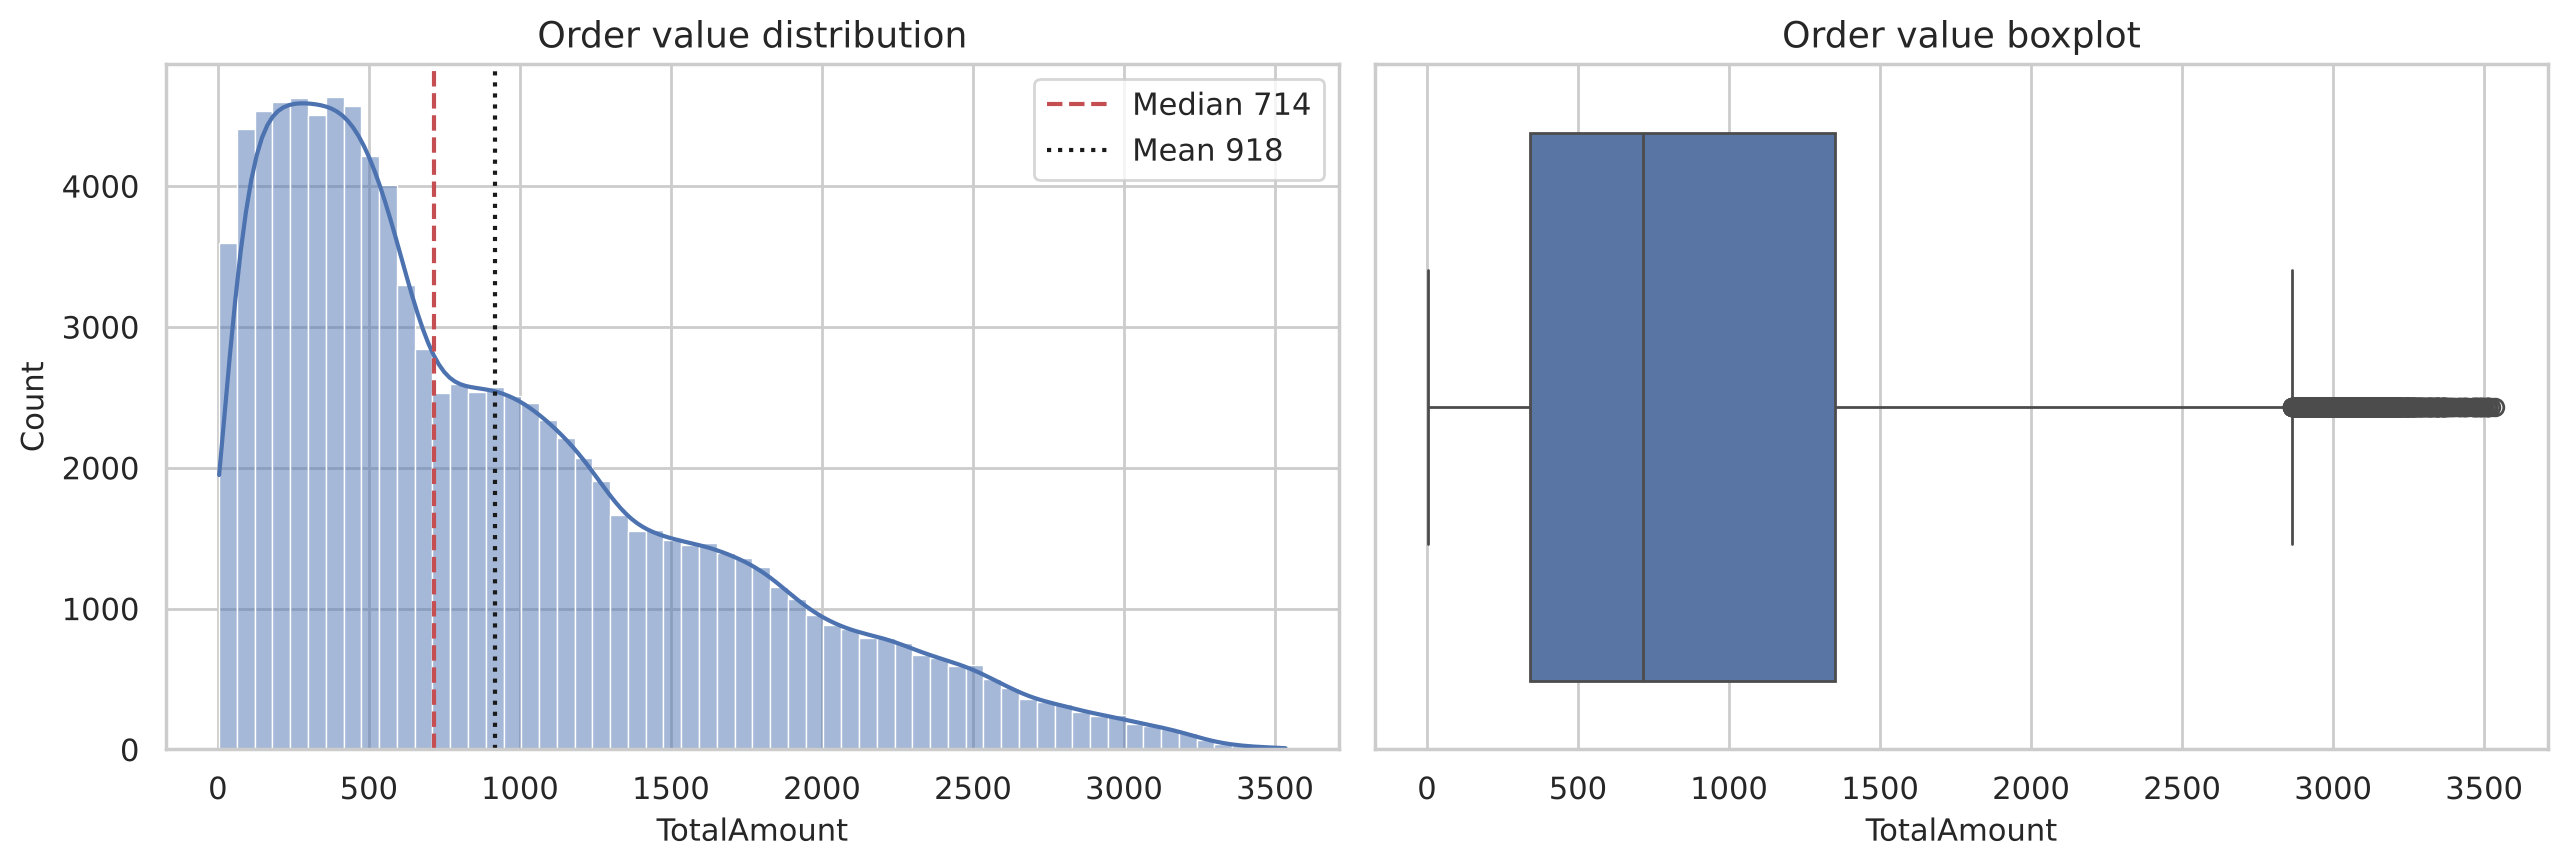

Skewness: 0.95 | Top 10% of orders contribute 26.7% of revenue


In [ ]:
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
sns.histplot(df.TotalAmount,bins=60,kde=True,ax=ax[0]); ax[0].axvline(df.TotalAmount.median(),color='r',ls='--',label=f'Median {df.TotalAmount.median():,.0f}')
ax[0].axvline(df.TotalAmount.mean(),color='k',ls=':',label=f'Mean {df.TotalAmount.mean():,.0f}'); ax[0].legend(); ax[0].set_title('Order value distribution')
sns.boxplot(x=df.TotalAmount,ax=ax[1]); ax[1].set_title('Order value boxplot')
plt.tight_layout(); plt.show()
top10=df.TotalAmount.quantile(.9); share=df.loc[df.TotalAmount>=top10,'TotalAmount'].sum()/df.TotalAmount.sum()
print(f'Skewness: {df.TotalAmount.skew():.2f} | Top 10% of orders contribute {share:.1%} of revenue')

**Insight:** Mild right skew (≈0.95): mean (~918) sits above median (~714). The top 10% of orders bring roughly a quarter of revenue — notable but not extreme concentration. The tail comes from high-quantity × high-price orders, not outliers or errors.

### 3.2 Pricing spread

UnitPrice median: 303.07 | variance: 29529.3 | CV: 0.57


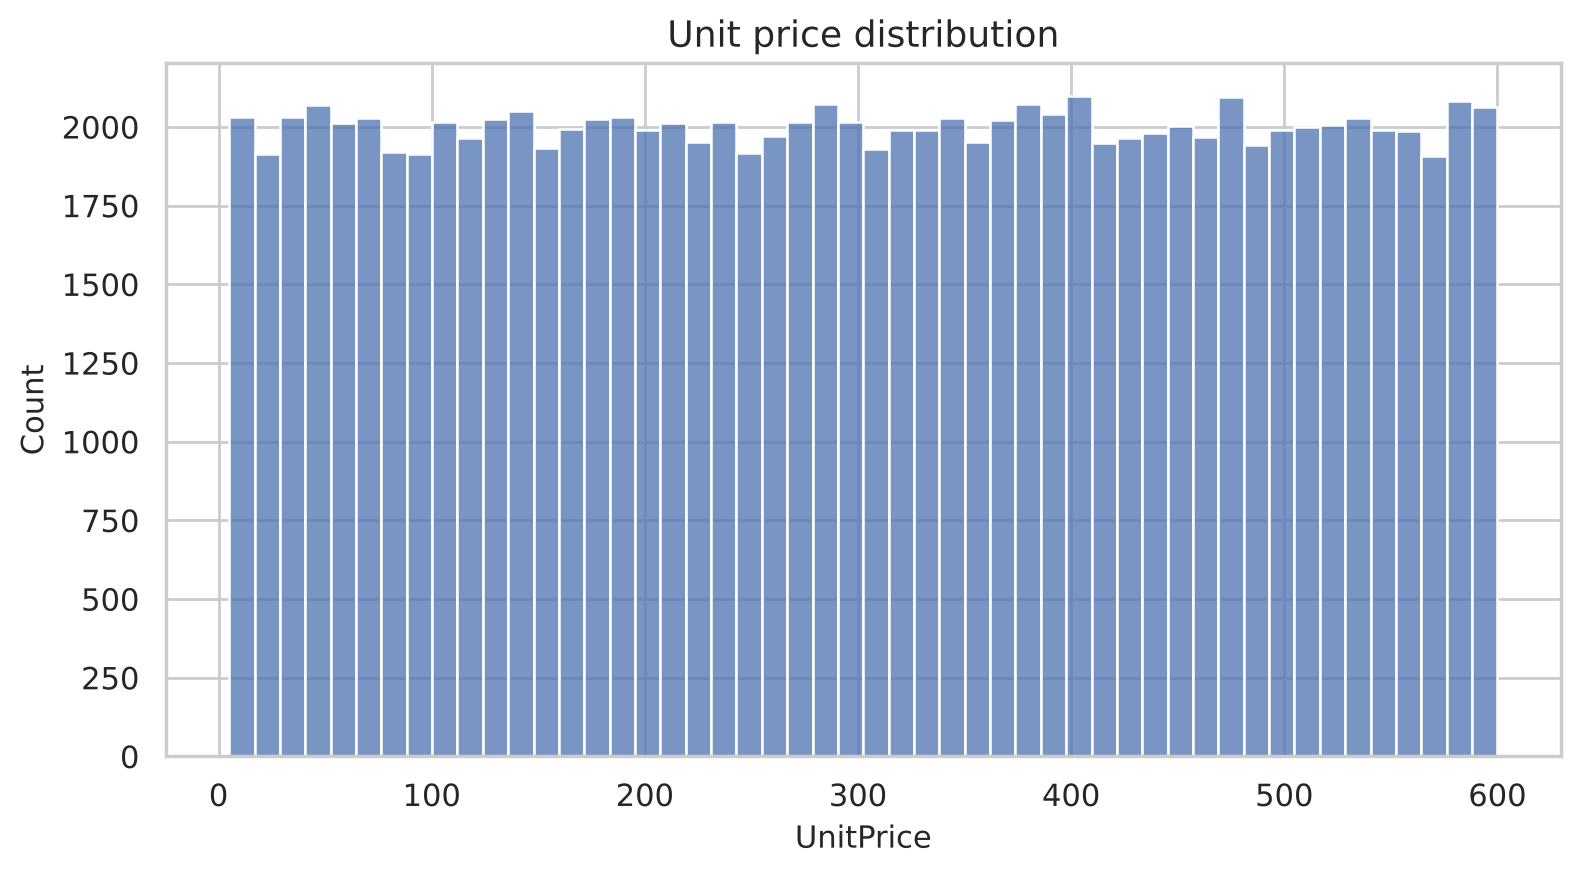

In [ ]:
print('UnitPrice median:',df.UnitPrice.median(),'| variance:',round(df.UnitPrice.var(),1),'| CV:',round(df.UnitPrice.std()/df.UnitPrice.mean(),2))
sns.histplot(df.UnitPrice,bins=50); plt.title('Unit price distribution'); plt.show()

**Insight:** UnitPrice is close to uniform between ~5 and 600 — a very wide catalogue with no dominant price point (CV ≈ 0.57).

### 3.3 Discount sensitivity & 3.4 Fulfilment status

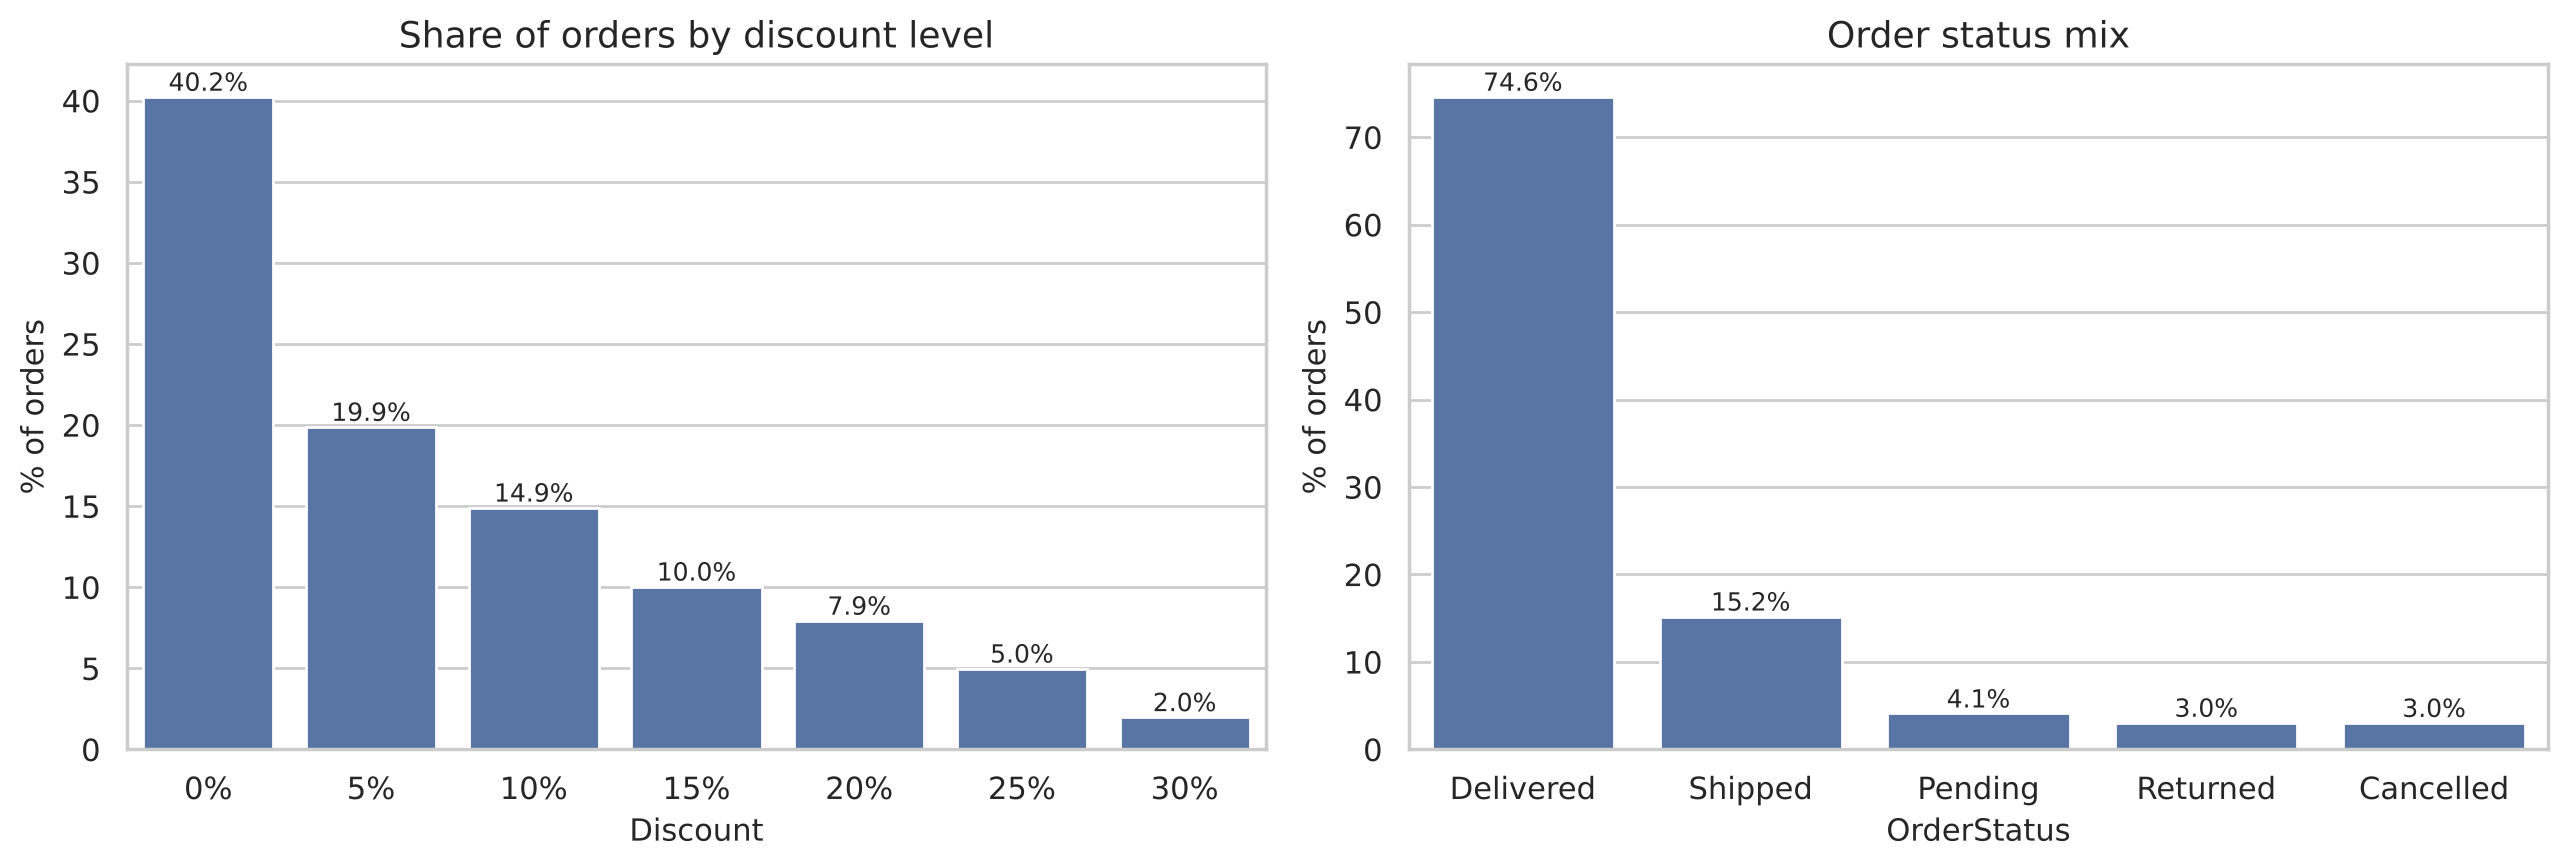

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
d=df.Discount.value_counts(normalize=True).sort_index()*100
sns.barplot(x=(d.index*100).astype(int).astype(str)+'%',y=d.values,ax=ax[0]); ax[0].set_title('Share of orders by discount level'); ax[0].set_ylabel('% of orders')
s=df.OrderStatus.value_counts(normalize=True).mul(100)
sns.barplot(x=s.index,y=s.values,ax=ax[1]); ax[1].set_title('Order status mix'); ax[1].set_ylabel('% of orders')
for a in ax:
    for p in a.patches: a.annotate(f'{p.get_height():.1f}%',(p.get_x()+p.get_width()/2,p.get_height()),ha='center',va='bottom',fontsize=9)
plt.tight_layout(); plt.show()

**Insights**
- **40% of orders sell at full price**; only 7% carry ≥20% discounts. Discounting is shallow and skewed to small levels.
- Only **74.6% of orders are Delivered**. 3.0% Cancelled + 3.0% Returned = **~6% leakage**; 15% still Shipped and 4% Pending.

### 3.5 Geographic concentration

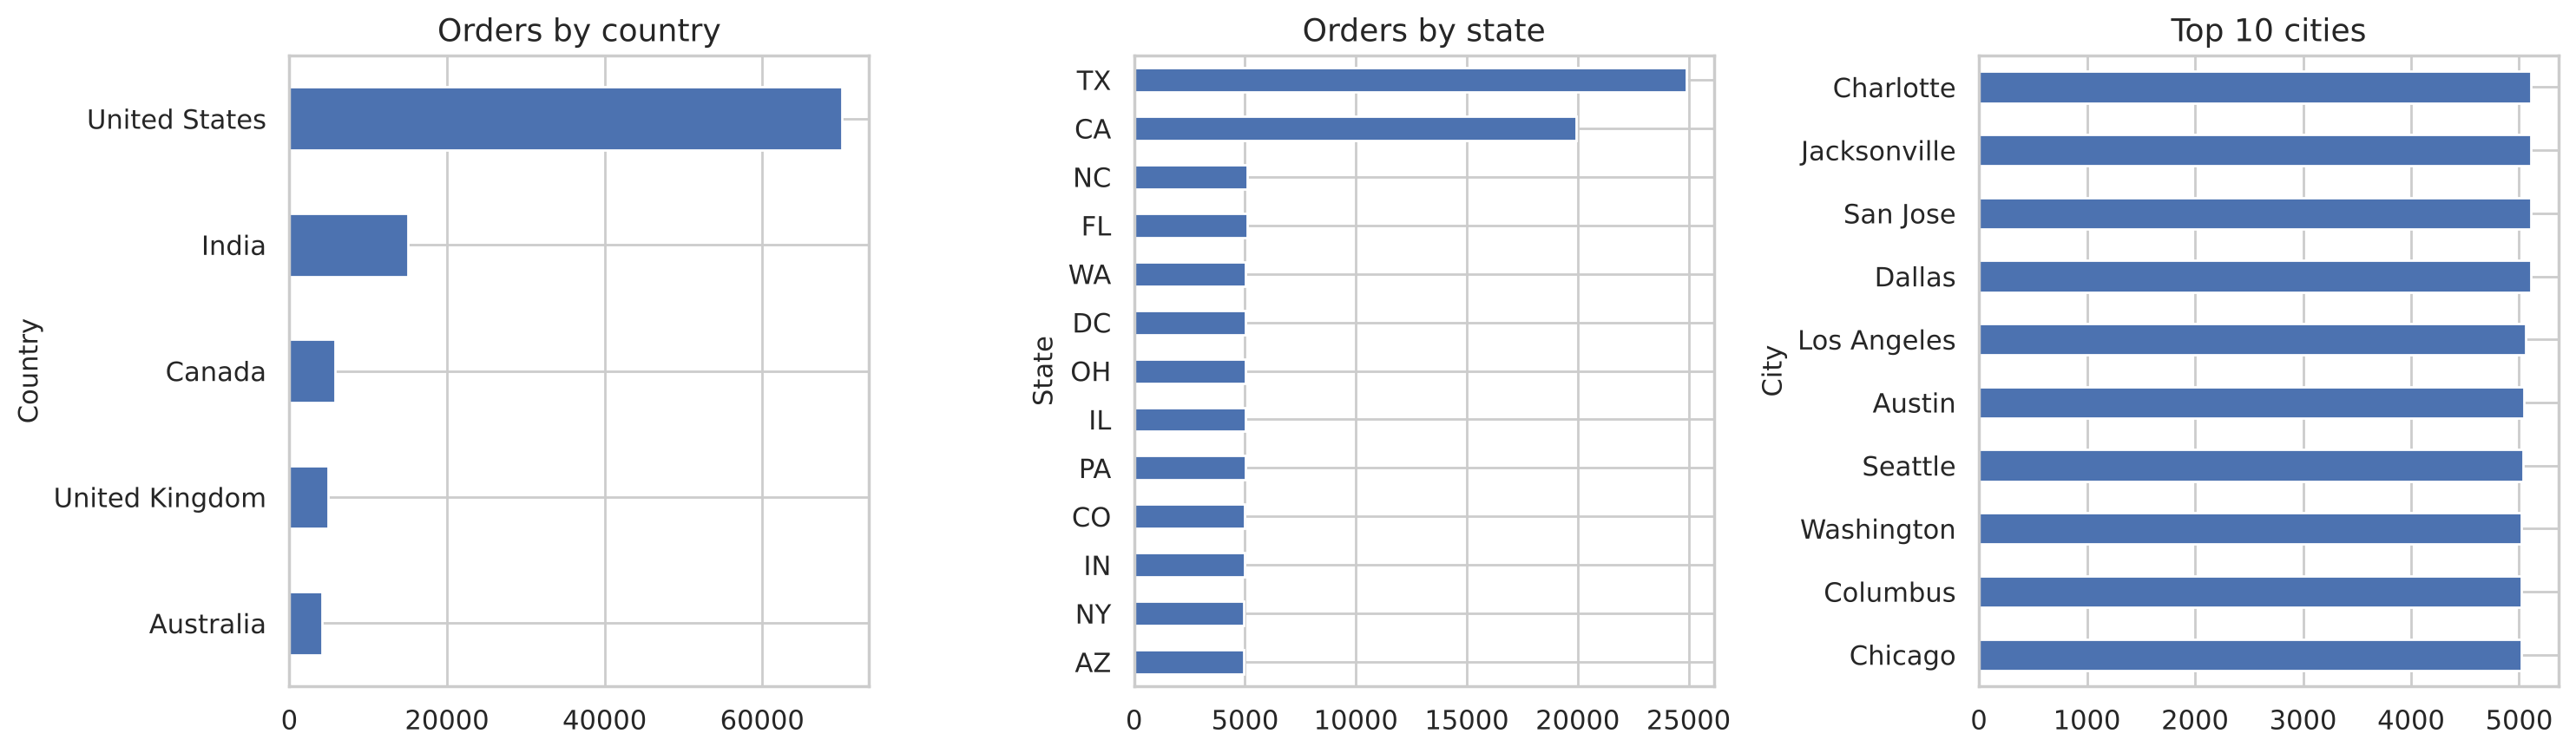

Country
United States    70.100
India            15.100
Canada            5.800
United Kingdom    4.900
Australia         4.100
Name: proportion, dtype: float64


In [ ]:
fig,ax=plt.subplots(1,3,figsize=(15,4.5))
df.Country.value_counts().plot.barh(ax=ax[0]).invert_yaxis(); ax[0].set_title('Orders by country')
df.State.value_counts().plot.barh(ax=ax[1]).invert_yaxis(); ax[1].set_title('Orders by state')
df.City.value_counts().head(10).plot.barh(ax=ax[2]).invert_yaxis(); ax[2].set_title('Top 10 cities')
plt.tight_layout(); plt.show()
print((df.Country.value_counts(normalize=True)*100).round(1))

**Insight:** The US accounts for **70%** of orders; India is second at 15%. Concentration in one market is both an opportunity and a dependency risk.

## 4. Bivariate Analysis

### 4.1 Discount vs. quantity — do discounts lift units?

Pearson r (Discount, Quantity): -0.0004


,avg_qty,avg_order_value,orders
Discount,,,
0.000,3.006,987.907,40246
0.050,2.995,942.946,19889
0.100,2.999,898.122,14910
0.150,2.999,841.706,10041
0.200,2.994,793.680,7939
0.250,2.996,746.731,4986
0.300,3.048,726.645,1989


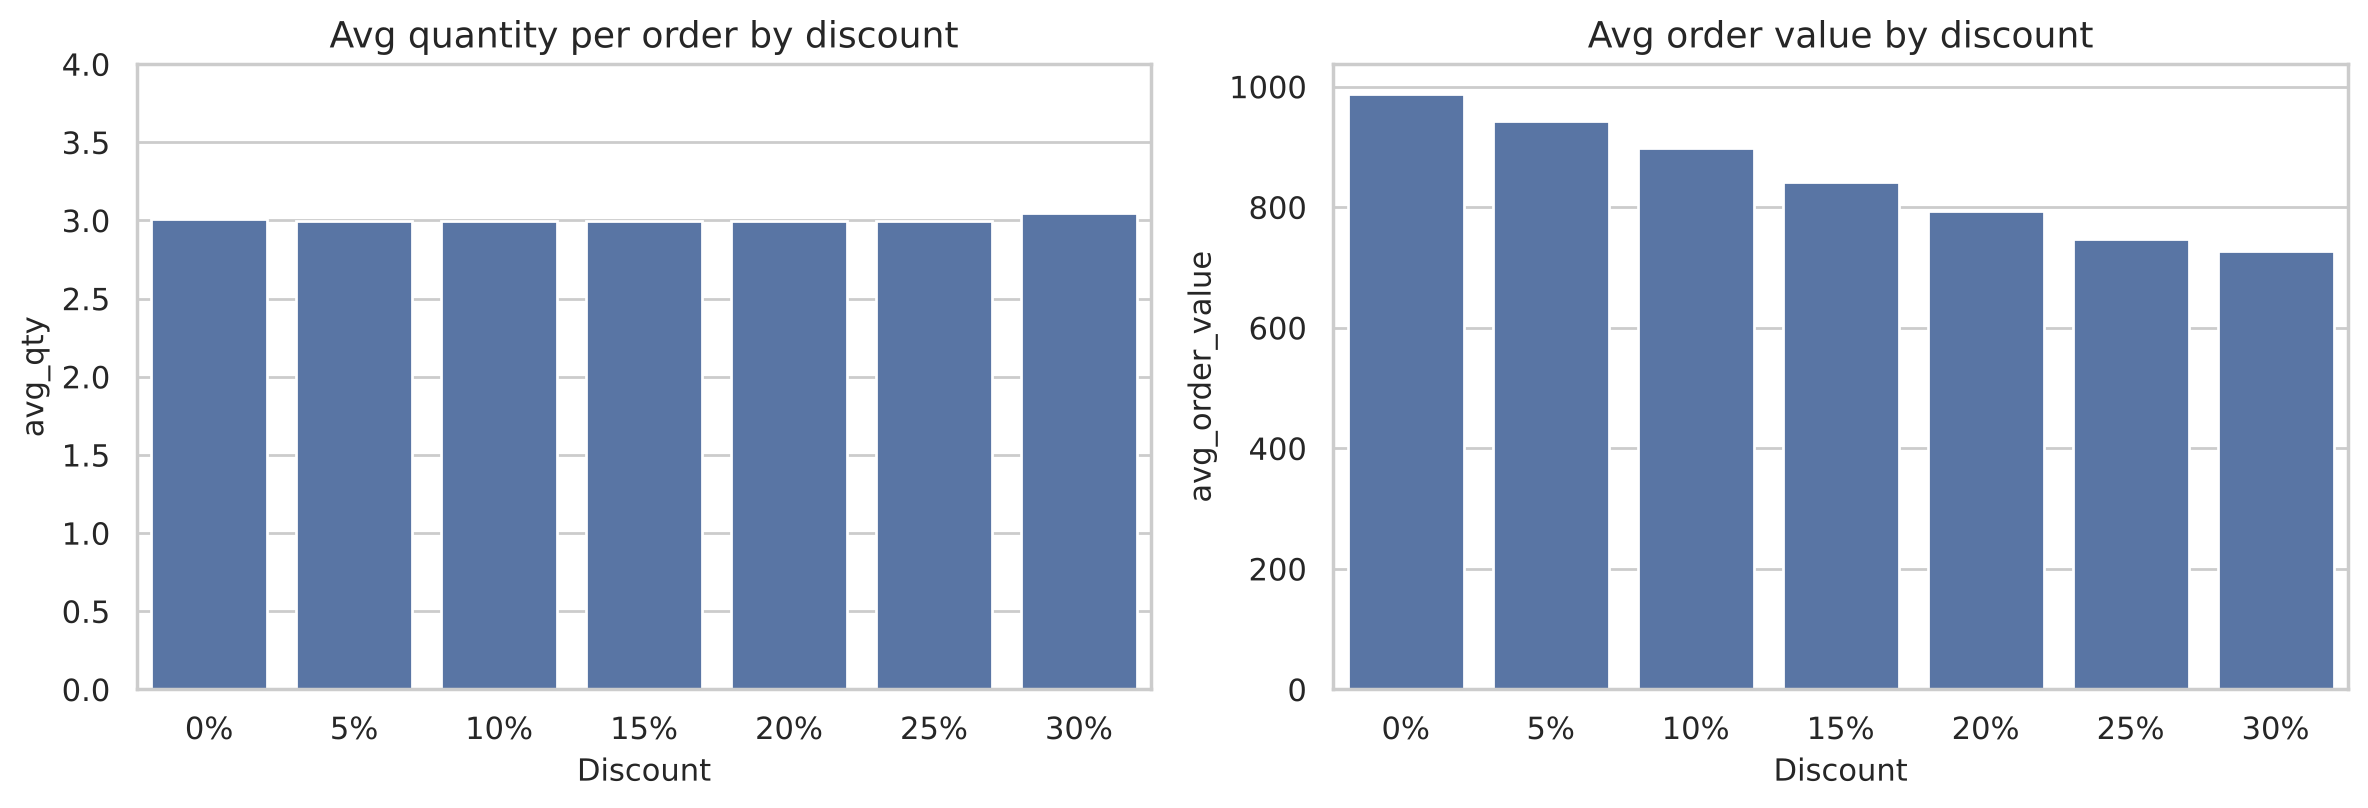

In [ ]:
print('Pearson r (Discount, Quantity):', round(df.Discount.corr(df.Quantity),4))
g=df.groupby('Discount').agg(avg_qty=('Quantity','mean'),avg_order_value=('TotalAmount','mean'),orders=('OrderID','count'))
display(g)
fig,ax=plt.subplots(1,2,figsize=(12,4.2))
sns.barplot(x=(g.index*100).astype(int).astype(str)+'%',y=g.avg_qty,ax=ax[0]); ax[0].set_ylim(0,4); ax[0].set_title('Avg quantity per order by discount'); ax[0].set_xlabel('Discount')
sns.barplot(x=(g.index*100).astype(int).astype(str)+'%',y=g.avg_order_value,ax=ax[1]); ax[1].set_title('Avg order value by discount'); ax[1].set_xlabel('Discount')
plt.tight_layout(); plt.show()

**Key insight:** Correlation is **≈ 0.00**. Customers buy ~3.0 units at every discount level, so discounts do **not** generate extra volume. Average order value instead falls steadily (≈988 at 0% → ≈727 at 30%) — discounts are pure margin give-away in this data.

### 4.2 Category & brand revenue vs. order count

,revenue,orders,aov
Category,,,
Electronics,"15,584,217.180",16853,924.715
Sports & Outdoors,"15,345,571.880",16804,913.209
Books,"15,261,837.010",16752,911.046
Clothing,"15,253,397.500",16439,927.879
Toys & Games,"15,216,684.990",16542,919.882
Home & Kitchen,"15,163,939.360",16610,912.940


,revenue,orders,aov
Brand,,,
CoreTech,"9,343,720.590",10127,922.654
KiddoFun,"9,324,749.550",10077,925.350
ReadMore,"9,278,406.630",10204,909.291
UrbanStyle,"9,249,027.450",9854,938.606
Zenith,"9,239,960.390",9990,924.921
Apex,"9,147,604.720",9937,920.560
NexPro,"9,078,824.970",9962,911.346
FitLife,"9,061,444.680",10147,893.017
BrightLux,"9,056,816.110",9907,914.184


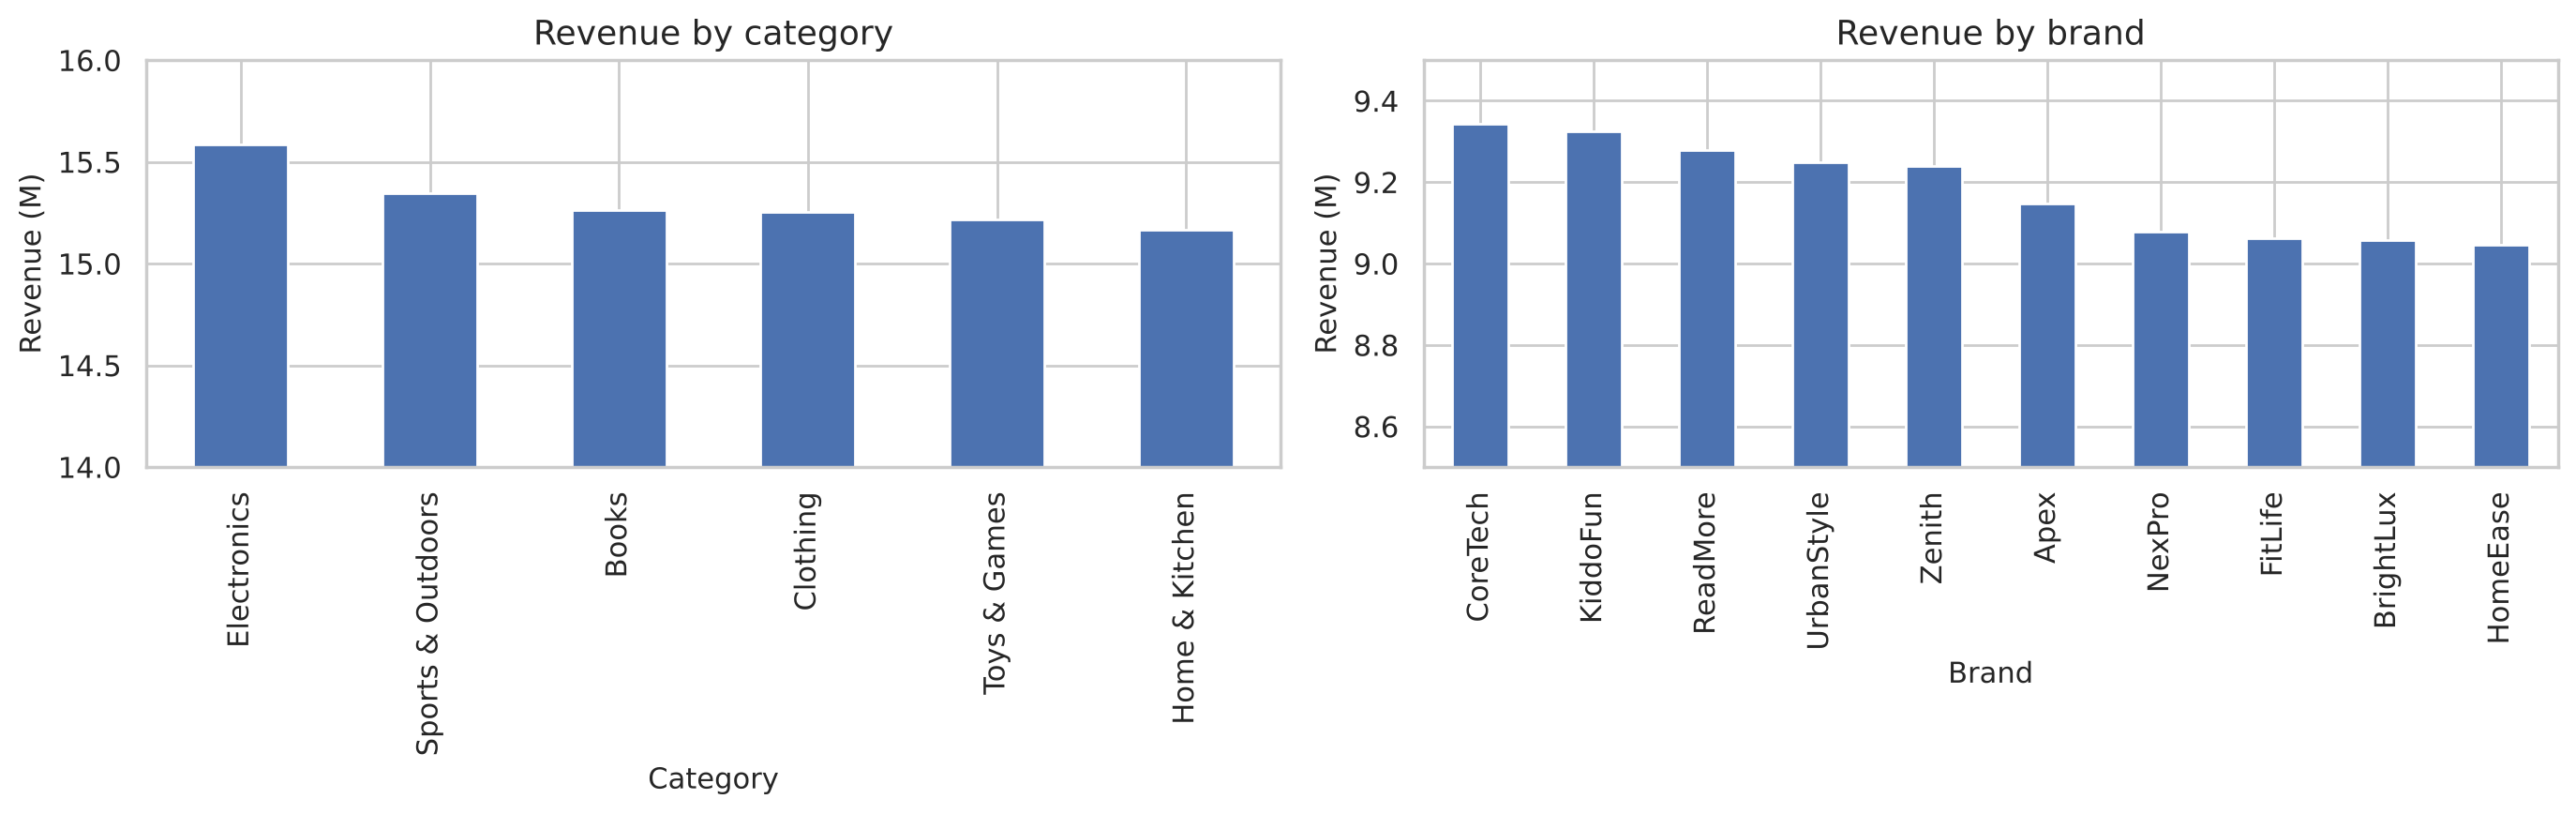

In [ ]:
cat=df.groupby('Category').agg(revenue=('TotalAmount','sum'),orders=('OrderID','count'),aov=('TotalAmount','mean')).sort_values('revenue',ascending=False)
brand=df.groupby('Brand').agg(revenue=('TotalAmount','sum'),orders=('OrderID','count'),aov=('TotalAmount','mean')).sort_values('revenue',ascending=False)
display(cat); display(brand)
fig,ax=plt.subplots(1,2,figsize=(14,4.5))
(cat.revenue/1e6).plot.bar(ax=ax[0]); ax[0].set_ylabel('Revenue (M)'); ax[0].set_title('Revenue by category'); ax[0].set_ylim(14,16)
(brand.revenue/1e6).plot.bar(ax=ax[1]); ax[1].set_ylabel('Revenue (M)'); ax[1].set_title('Revenue by brand'); ax[1].set_ylim(8.5,9.5)
plt.tight_layout(); plt.show()

**Insight:** Electronics leads (≈15.6M) but only ~2–3% ahead of the weakest category; brands are similarly flat (9.0–9.3M). *Note the truncated y-axis to make small gaps visible — the portfolio is effectively balanced.*

### 4.3 Payment method vs. order value

,orders,aov,cancel_rate,return_rate
PaymentMethod,,,,
Amazon Pay,15017,912.133,0.031,0.031
Cash on Delivery,4928,916.317,0.032,0.029
Credit Card,35038,916.781,0.031,0.031
Debit Card,20024,925.823,0.030,0.030
Net Banking,9927,912.227,0.029,0.032
UPI,15066,922.344,0.029,0.029


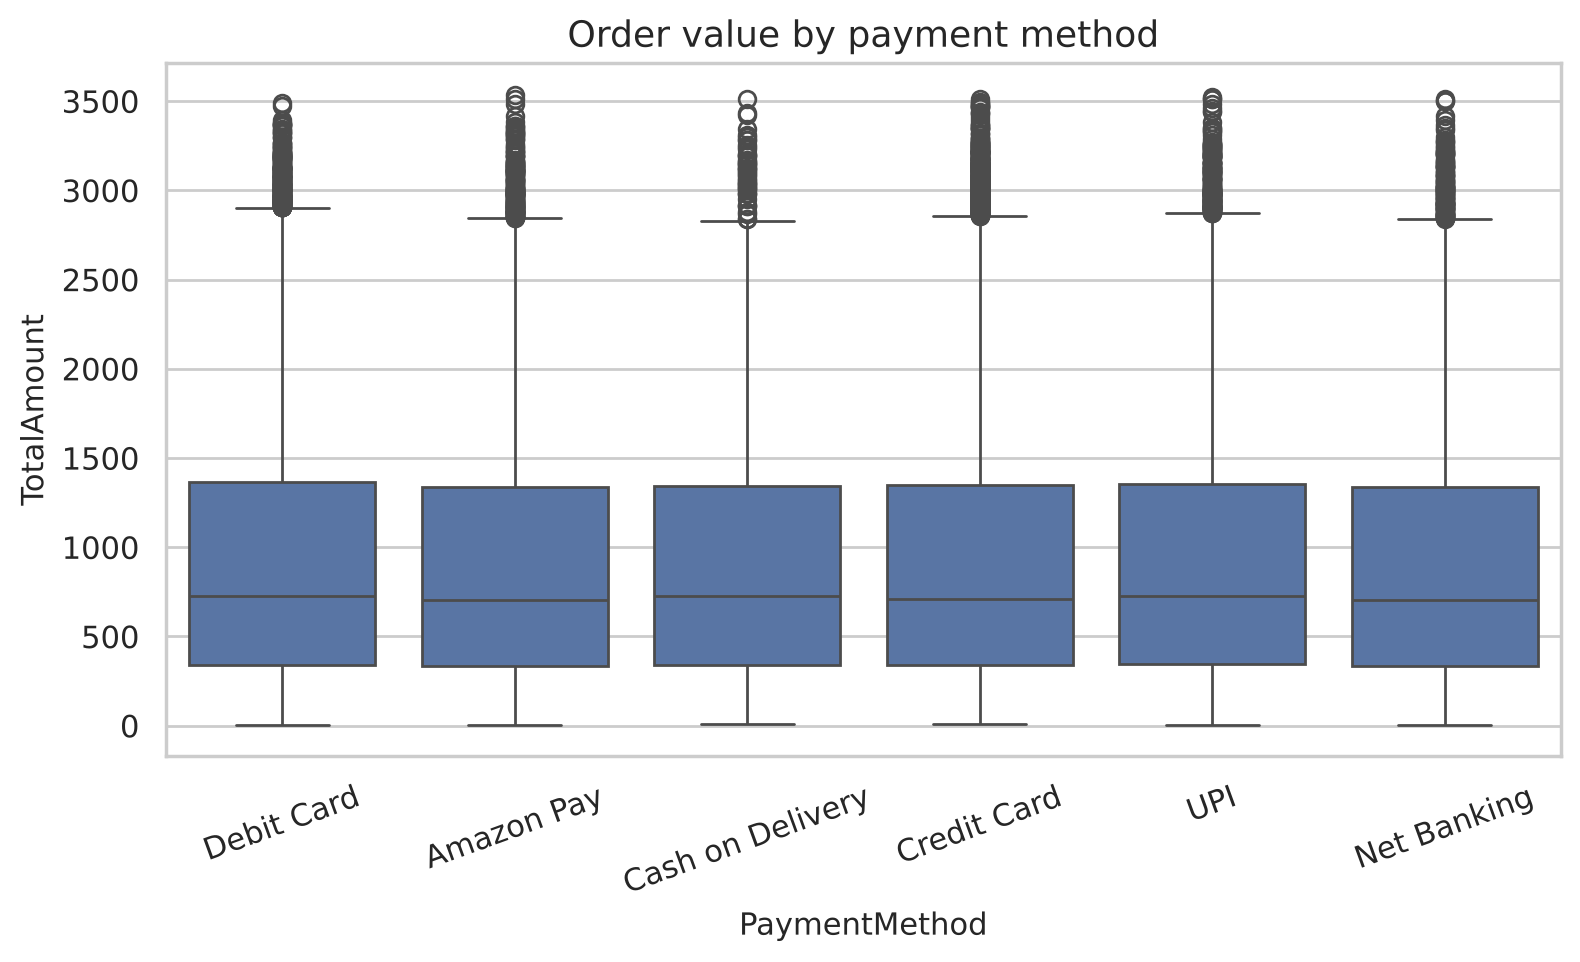

In [ ]:
pm=df.groupby('PaymentMethod').agg(orders=('OrderID','count'),aov=('TotalAmount','mean'),cancel_rate=('is_cancelled','mean'),return_rate=('is_returned','mean'))
display(pm)
sns.boxplot(data=df,x='PaymentMethod',y='TotalAmount'); plt.xticks(rotation=20); plt.title('Order value by payment method'); plt.show()

**Insight:** Credit Card is the most used (35%), followed by Debit Card (20%), UPI/Amazon Pay (15% each). AOV differs by <2% across methods — formally tested in §7.

### 4.4 Shipping cost vs. order size

                 ShippingCost  TotalAmount  Quantity  GrossOrderValue
ShippingCost            1.000        0.039     0.020            0.034
TotalAmount             0.039        1.000     0.595            0.987
Quantity                0.020        0.595     1.000            0.602
GrossOrderValue         0.034        0.987     0.602            1.000


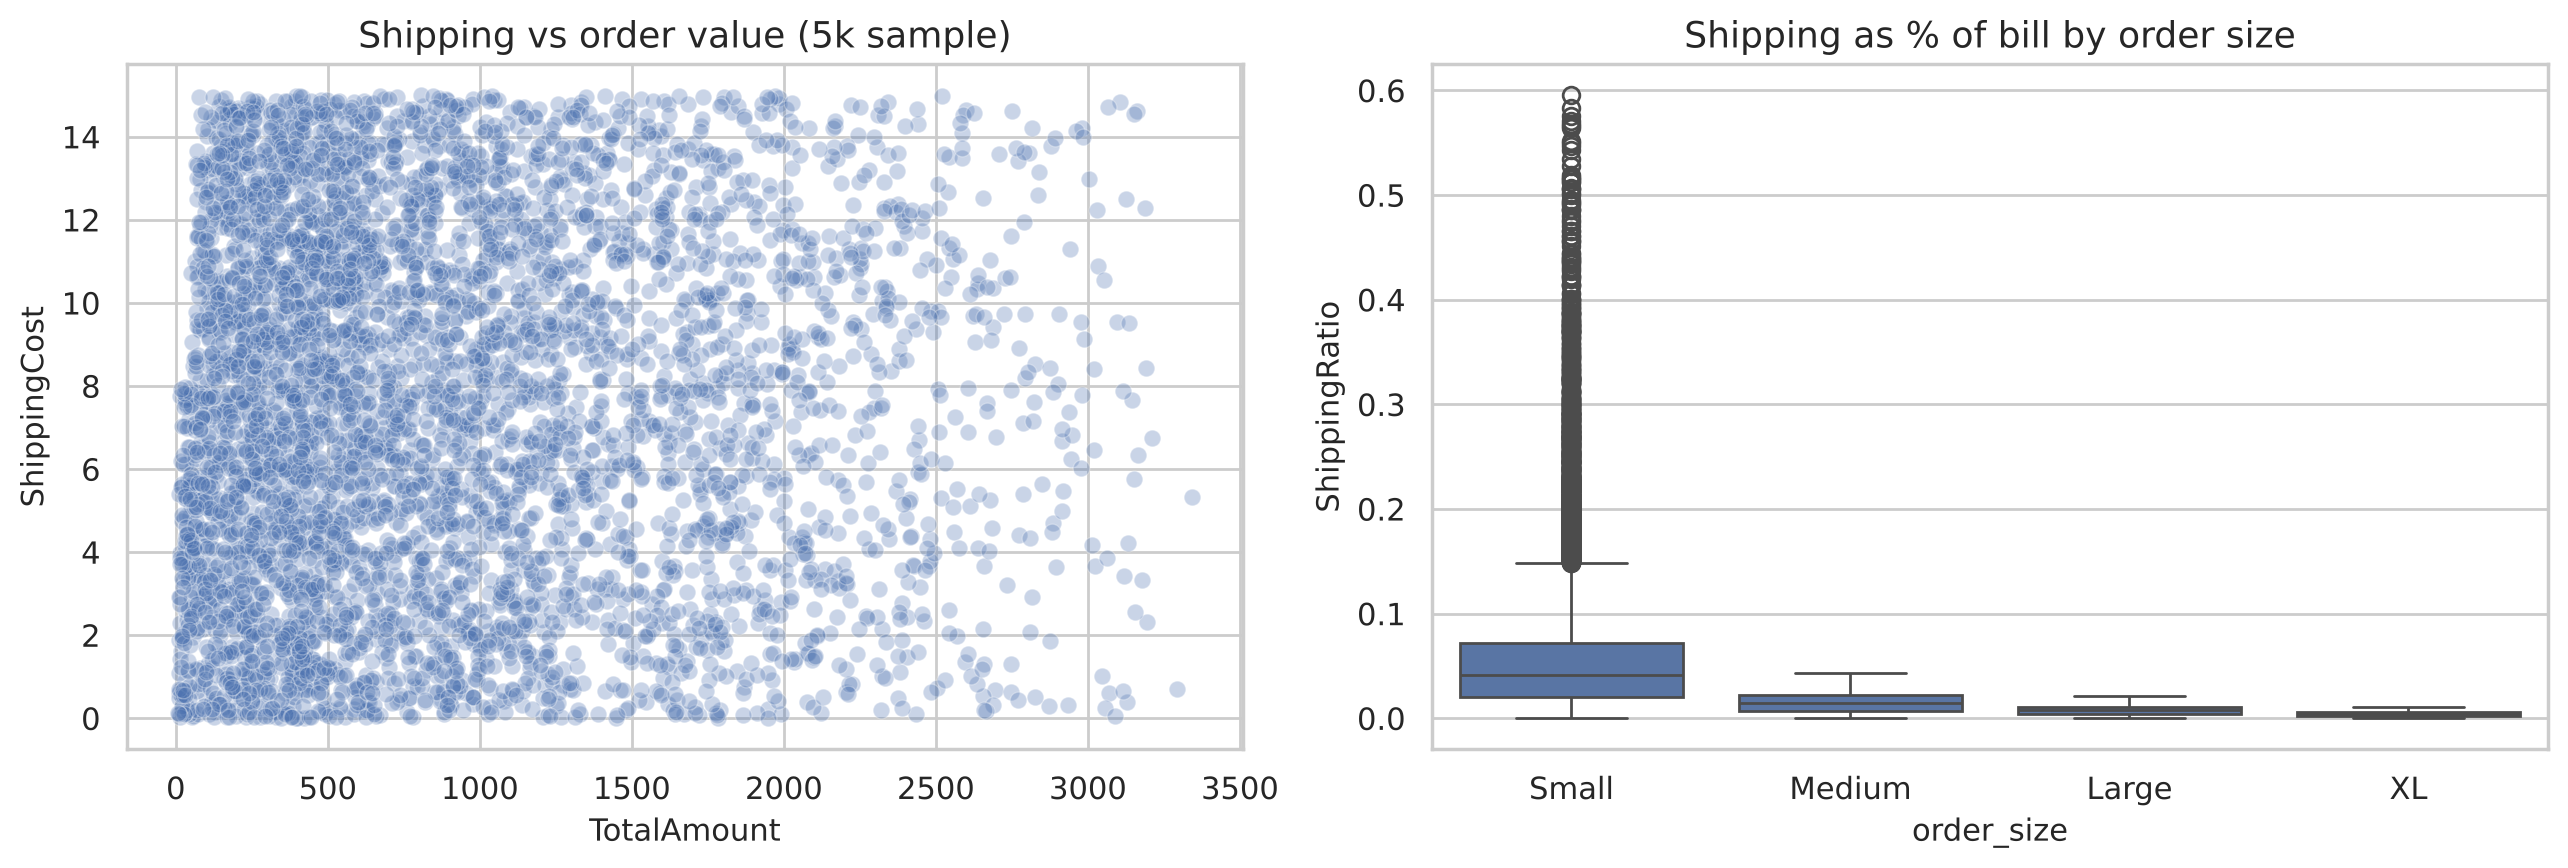

In [ ]:
print(df[['ShippingCost','TotalAmount','Quantity','GrossOrderValue']].corr().round(3))
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
sns.scatterplot(data=df.sample(5000,random_state=1),x='TotalAmount',y='ShippingCost',alpha=.3,ax=ax[0]); ax[0].set_title('Shipping vs order value (5k sample)')
sns.boxplot(data=df,x='order_size',y='ShippingRatio',ax=ax[1]); ax[1].set_title('Shipping as % of bill by order size')
plt.tight_layout(); plt.show()

**Insight:** Shipping is a flat random fee (0–15, mean ≈ 7.4); correlation with order value is only 0.04. As a result, **small orders pay a far higher shipping burden** (ratio of bill) than XL orders — a threshold for free shipping could be designed around this.

### 4.5 Seller performance variance

Sellers: 1999


,count,mean,std,min,25%,50%,75%,max
orders,"1,999.000",50.025,6.878,29.000,45.000,50.000,55.000,78.000
aov,"1,999.000",918.069,102.628,587.639,848.320,915.023,985.051,"1,231.023"
cancel_rate,"1,999.000",0.030,0.025,0.000,0.017,0.023,0.044,0.143


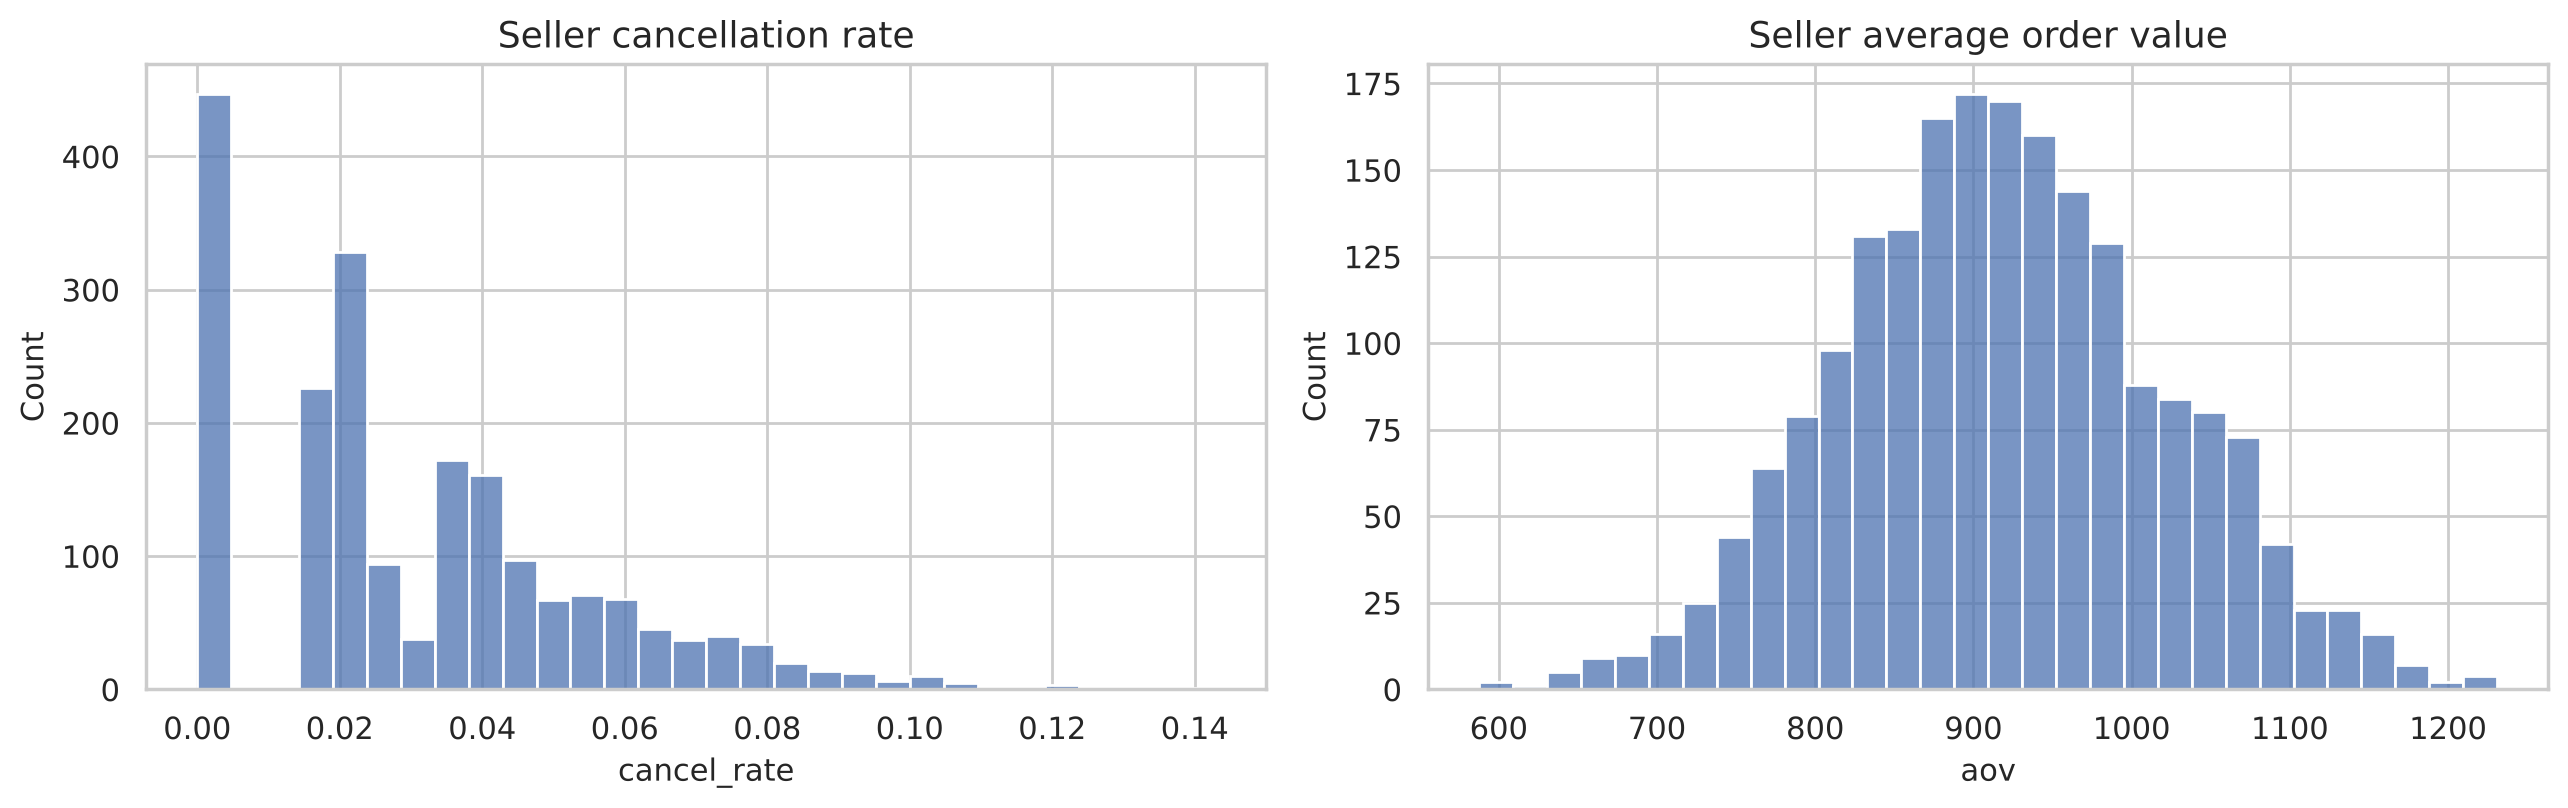

Observed std of seller cancel rate: 0.0247 | expected from pure chance: 0.0244


In [ ]:
sl=df.groupby('SellerID').agg(orders=('OrderID','count'),aov=('TotalAmount','mean'),cancel_rate=('is_cancelled','mean'))
print('Sellers:',len(sl)); display(sl.describe().T)
fig,ax=plt.subplots(1,2,figsize=(13,4.2))
sns.histplot(sl.cancel_rate,bins=30,ax=ax[0]); ax[0].set_title('Seller cancellation rate')
sns.histplot(sl.aov,bins=30,ax=ax[1]); ax[1].set_title('Seller average order value')
plt.tight_layout(); plt.show()
# Is the spread more than expected by chance? Compare with binomial simulation
sim=np.random.default_rng(0).binomial(sl.orders,df.is_cancelled.mean())/sl.orders
print(f'Observed std of seller cancel rate: {sl.cancel_rate.std():.4f} | expected from pure chance: {sim.std():.4f}')

**Insight:** Each of 1,999 sellers has only ~50 orders, so seller-level rates are noisy. The observed spread in cancellation rate matches what pure chance would produce — i.e. **no seller is a statistically reliable outlier**; track sellers on a rolling window of larger volume before acting.

## 5. Multivariate Analysis

### 5.1 Category × price bracket × discount

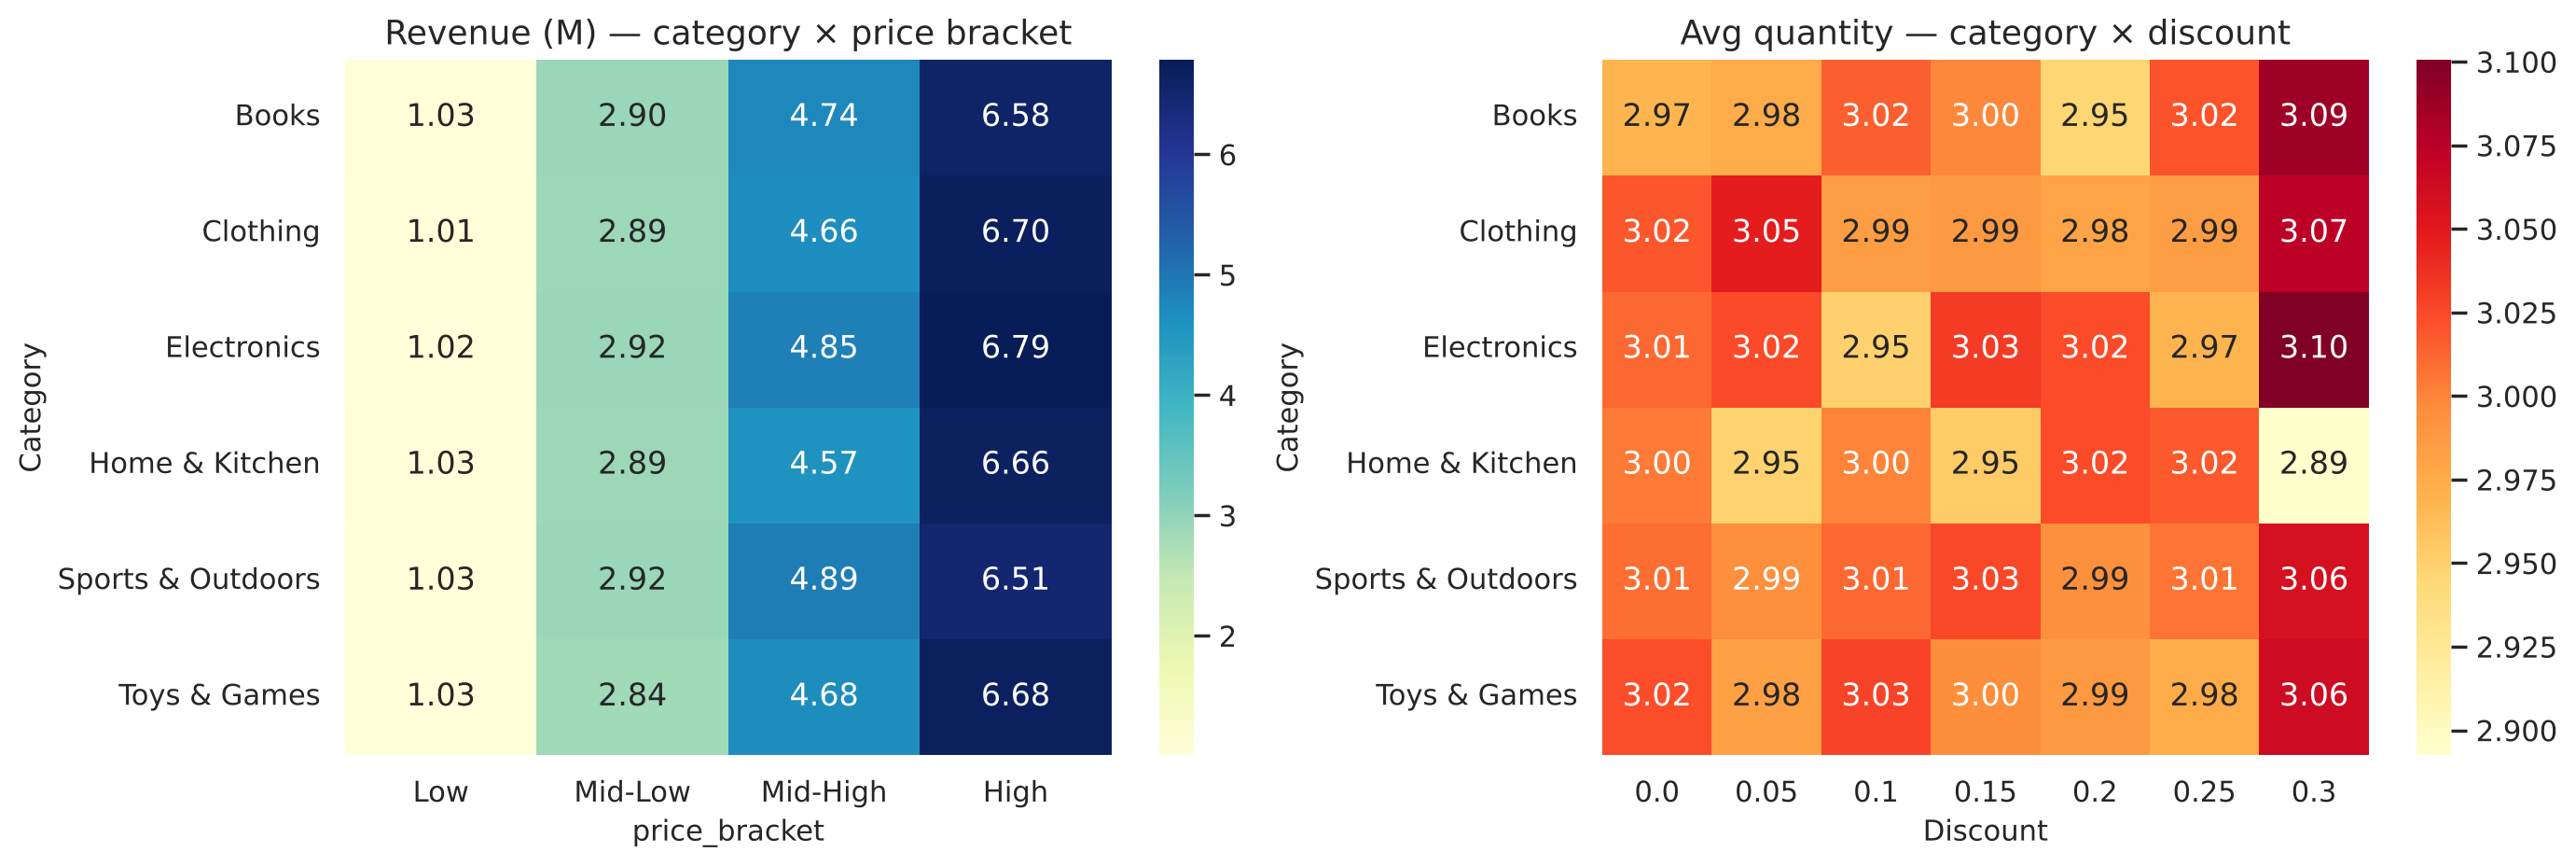

In [ ]:
pv=df.pivot_table(index='Category',columns='price_bracket',values='TotalAmount',aggfunc='sum',observed=True)/1e6
fig,ax=plt.subplots(1,2,figsize=(14,4.8))
sns.heatmap(pv,annot=True,fmt='.2f',cmap='YlGnBu',ax=ax[0]); ax[0].set_title('Revenue (M) — category × price bracket')
pv2=df.pivot_table(index='Category',columns='Discount',values='Quantity',aggfunc='mean')
sns.heatmap(pv2,annot=True,fmt='.2f',cmap='YlOrRd',ax=ax[1]); ax[1].set_title('Avg quantity — category × discount')
plt.tight_layout(); plt.show()

**Insight:** Revenue is dominated by the **High and Mid-High price brackets in every category** (higher unit price drives revenue, as expected), while units per order stay ≈3 irrespective of category or discount — price level, not discounting, drives value.

### 5.2 Geographic cancellation drivers — state × payment method × order size

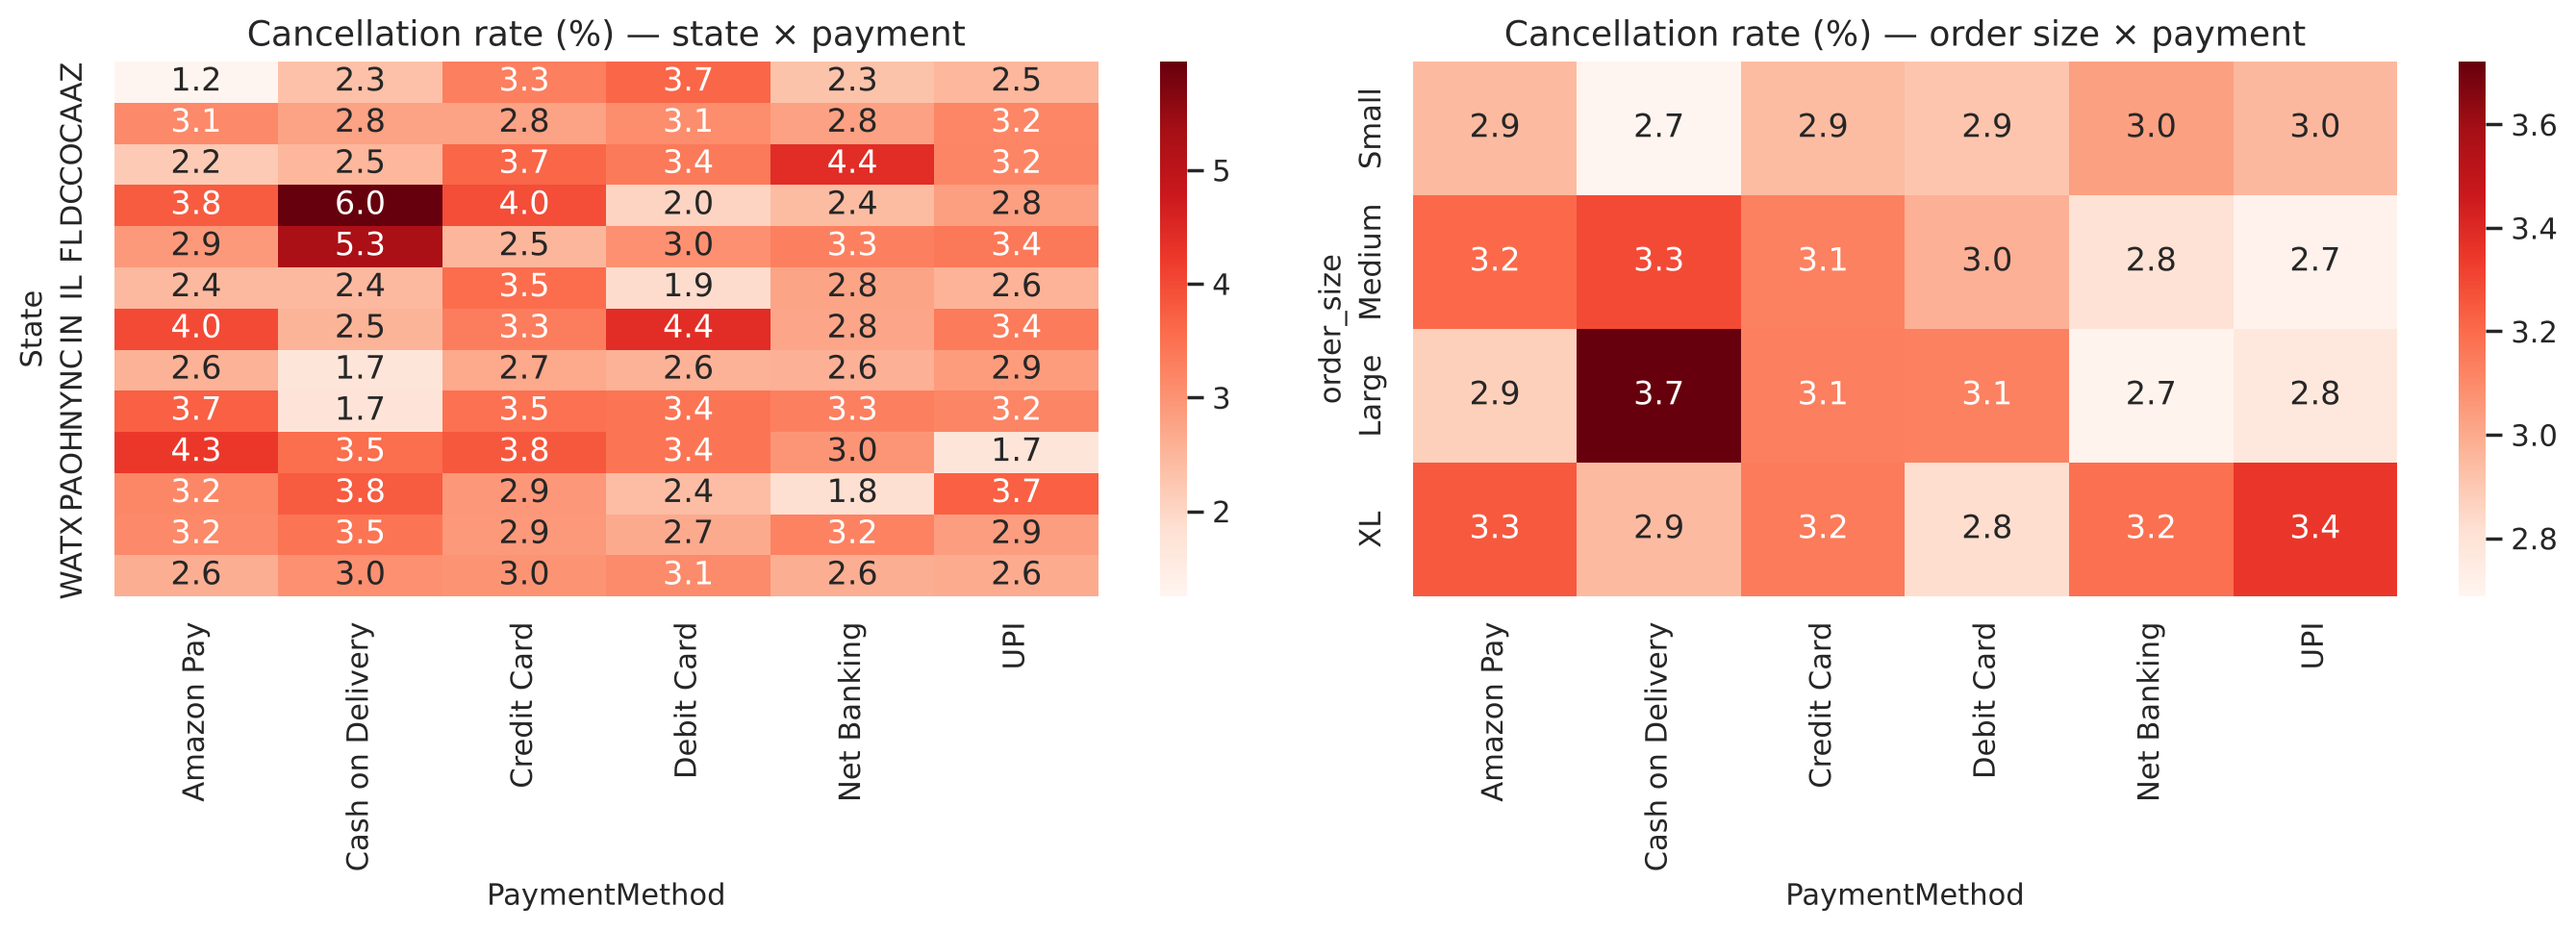

Highest/lowest state-level cancel rate: {'max': 3.56, 'min': 2.62}


In [ ]:
# Cancellation rate by state x payment method
pv=df.pivot_table(index='State',columns='PaymentMethod',values='is_cancelled',aggfunc='mean')*100
fig,ax=plt.subplots(1,2,figsize=(14,5))
sns.heatmap(pv,annot=True,fmt='.1f',cmap='Reds',ax=ax[0]); ax[0].set_title('Cancellation rate (%) — state × payment')
c=df.groupby(['order_size','PaymentMethod'],observed=True).is_cancelled.mean().unstack()*100
sns.heatmap(c,annot=True,fmt='.1f',cmap='Reds',ax=ax[1]); ax[1].set_title('Cancellation rate (%) — order size × payment')
plt.tight_layout(); plt.show()
print('Highest/lowest state-level cancel rate:',(df.groupby('State').is_cancelled.mean()*100).agg(['max','min']).round(2).to_dict())

**Insight:** Cell-to-cell variation (2–4%) is consistent with small-sample noise; **no state, payment method or order-size combination shows a dependable cancellation hot-spot.** Cancellation behaves as a uniform ~3% baseline risk.

### 5.3 Seller × category net realization

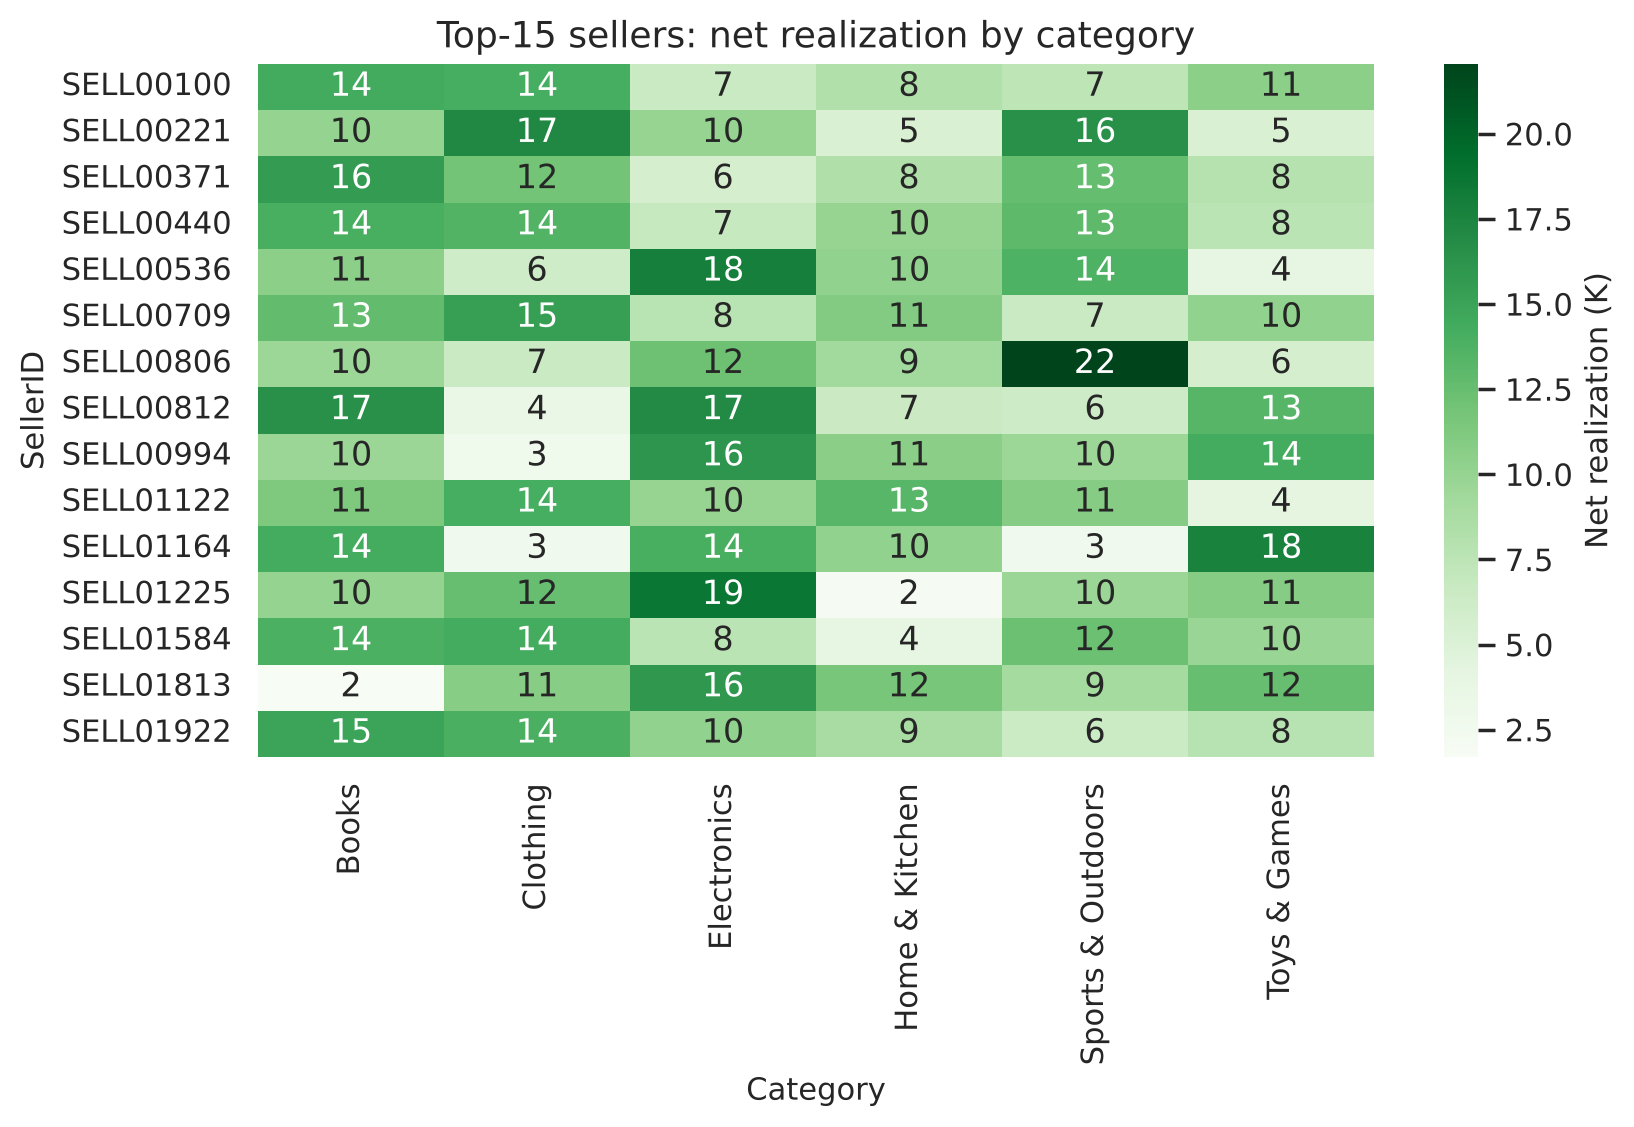

Category
Books               828.100
Clothing            844.200
Electronics         840.400
Home & Kitchen      829.600
Sports & Outdoors   830.600
Toys & Games        837.100
Name: NetRealization, dtype: float64


In [ ]:
df['NetRealization']=df.NetProduct-df.ShippingCost  # product revenue after shipping outlay (proxy)
top=df.groupby('SellerID').NetRealization.sum().nlargest(15).index
x=df[df.SellerID.isin(top)].pivot_table(index='SellerID',columns='Category',values='NetRealization',aggfunc='sum')
sns.heatmap(x/1e3,annot=True,fmt='.0f',cmap='Greens',cbar_kws={'label':'Net realization (K)'}); plt.title('Top-15 sellers: net realization by category'); plt.show()
print(df.groupby('Category').NetRealization.mean().round(1))

**Insight:** Net realization per order is nearly identical across categories (~835); top sellers are separated mainly by order count, not by category mix or shipping efficiency.

### 5.4 Discount & shipping across countries

,orders,avg_discount,avg_shipping,avg_qty,aov,cancel
Country,,,,,,
Australia,4130,0.075,7.446,3.011,917.459,0.030
Canada,5818,0.074,7.457,2.987,915.049,0.032
India,15051,0.074,7.389,2.995,921.921,0.029
United Kingdom,4943,0.076,7.330,3.000,915.820,0.031
United States,70058,0.074,7.409,3.003,917.954,0.030


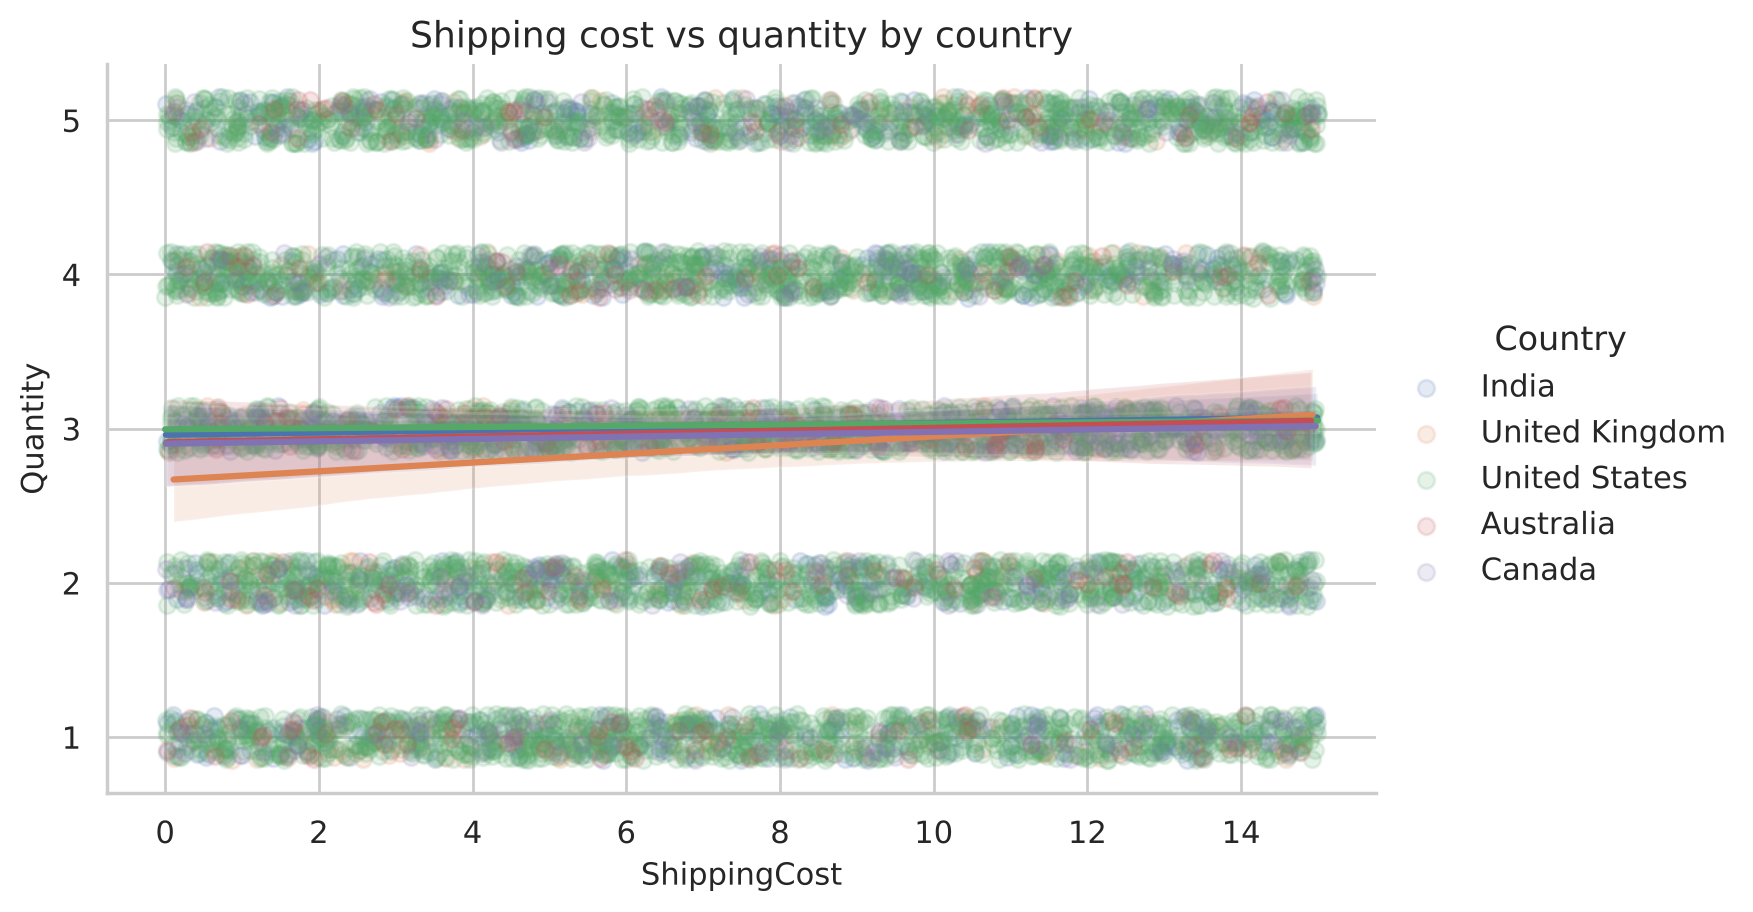

In [ ]:
cn=df.groupby('Country').agg(orders=('OrderID','count'),avg_discount=('Discount','mean'),avg_shipping=('ShippingCost','mean'),avg_qty=('Quantity','mean'),aov=('TotalAmount','mean'),cancel=('is_cancelled','mean'))
display(cn)
sns.lmplot(data=df.sample(8000,random_state=2),x='ShippingCost',y='Quantity',hue='Country',scatter_kws={'alpha':.15},height=4.5,aspect=1.6,x_jitter=0,y_jitter=.15)
plt.title('Shipping cost vs quantity by country'); plt.show()

**Insight:** Markets behave identically — average discount ≈10%, shipping ≈7.4, quantity ≈3, AOV ≈ 915–922 — so a single global pricing/discount strategy is just as effective as country-specific ones **in this data**.

## 6. Temporal Analysis

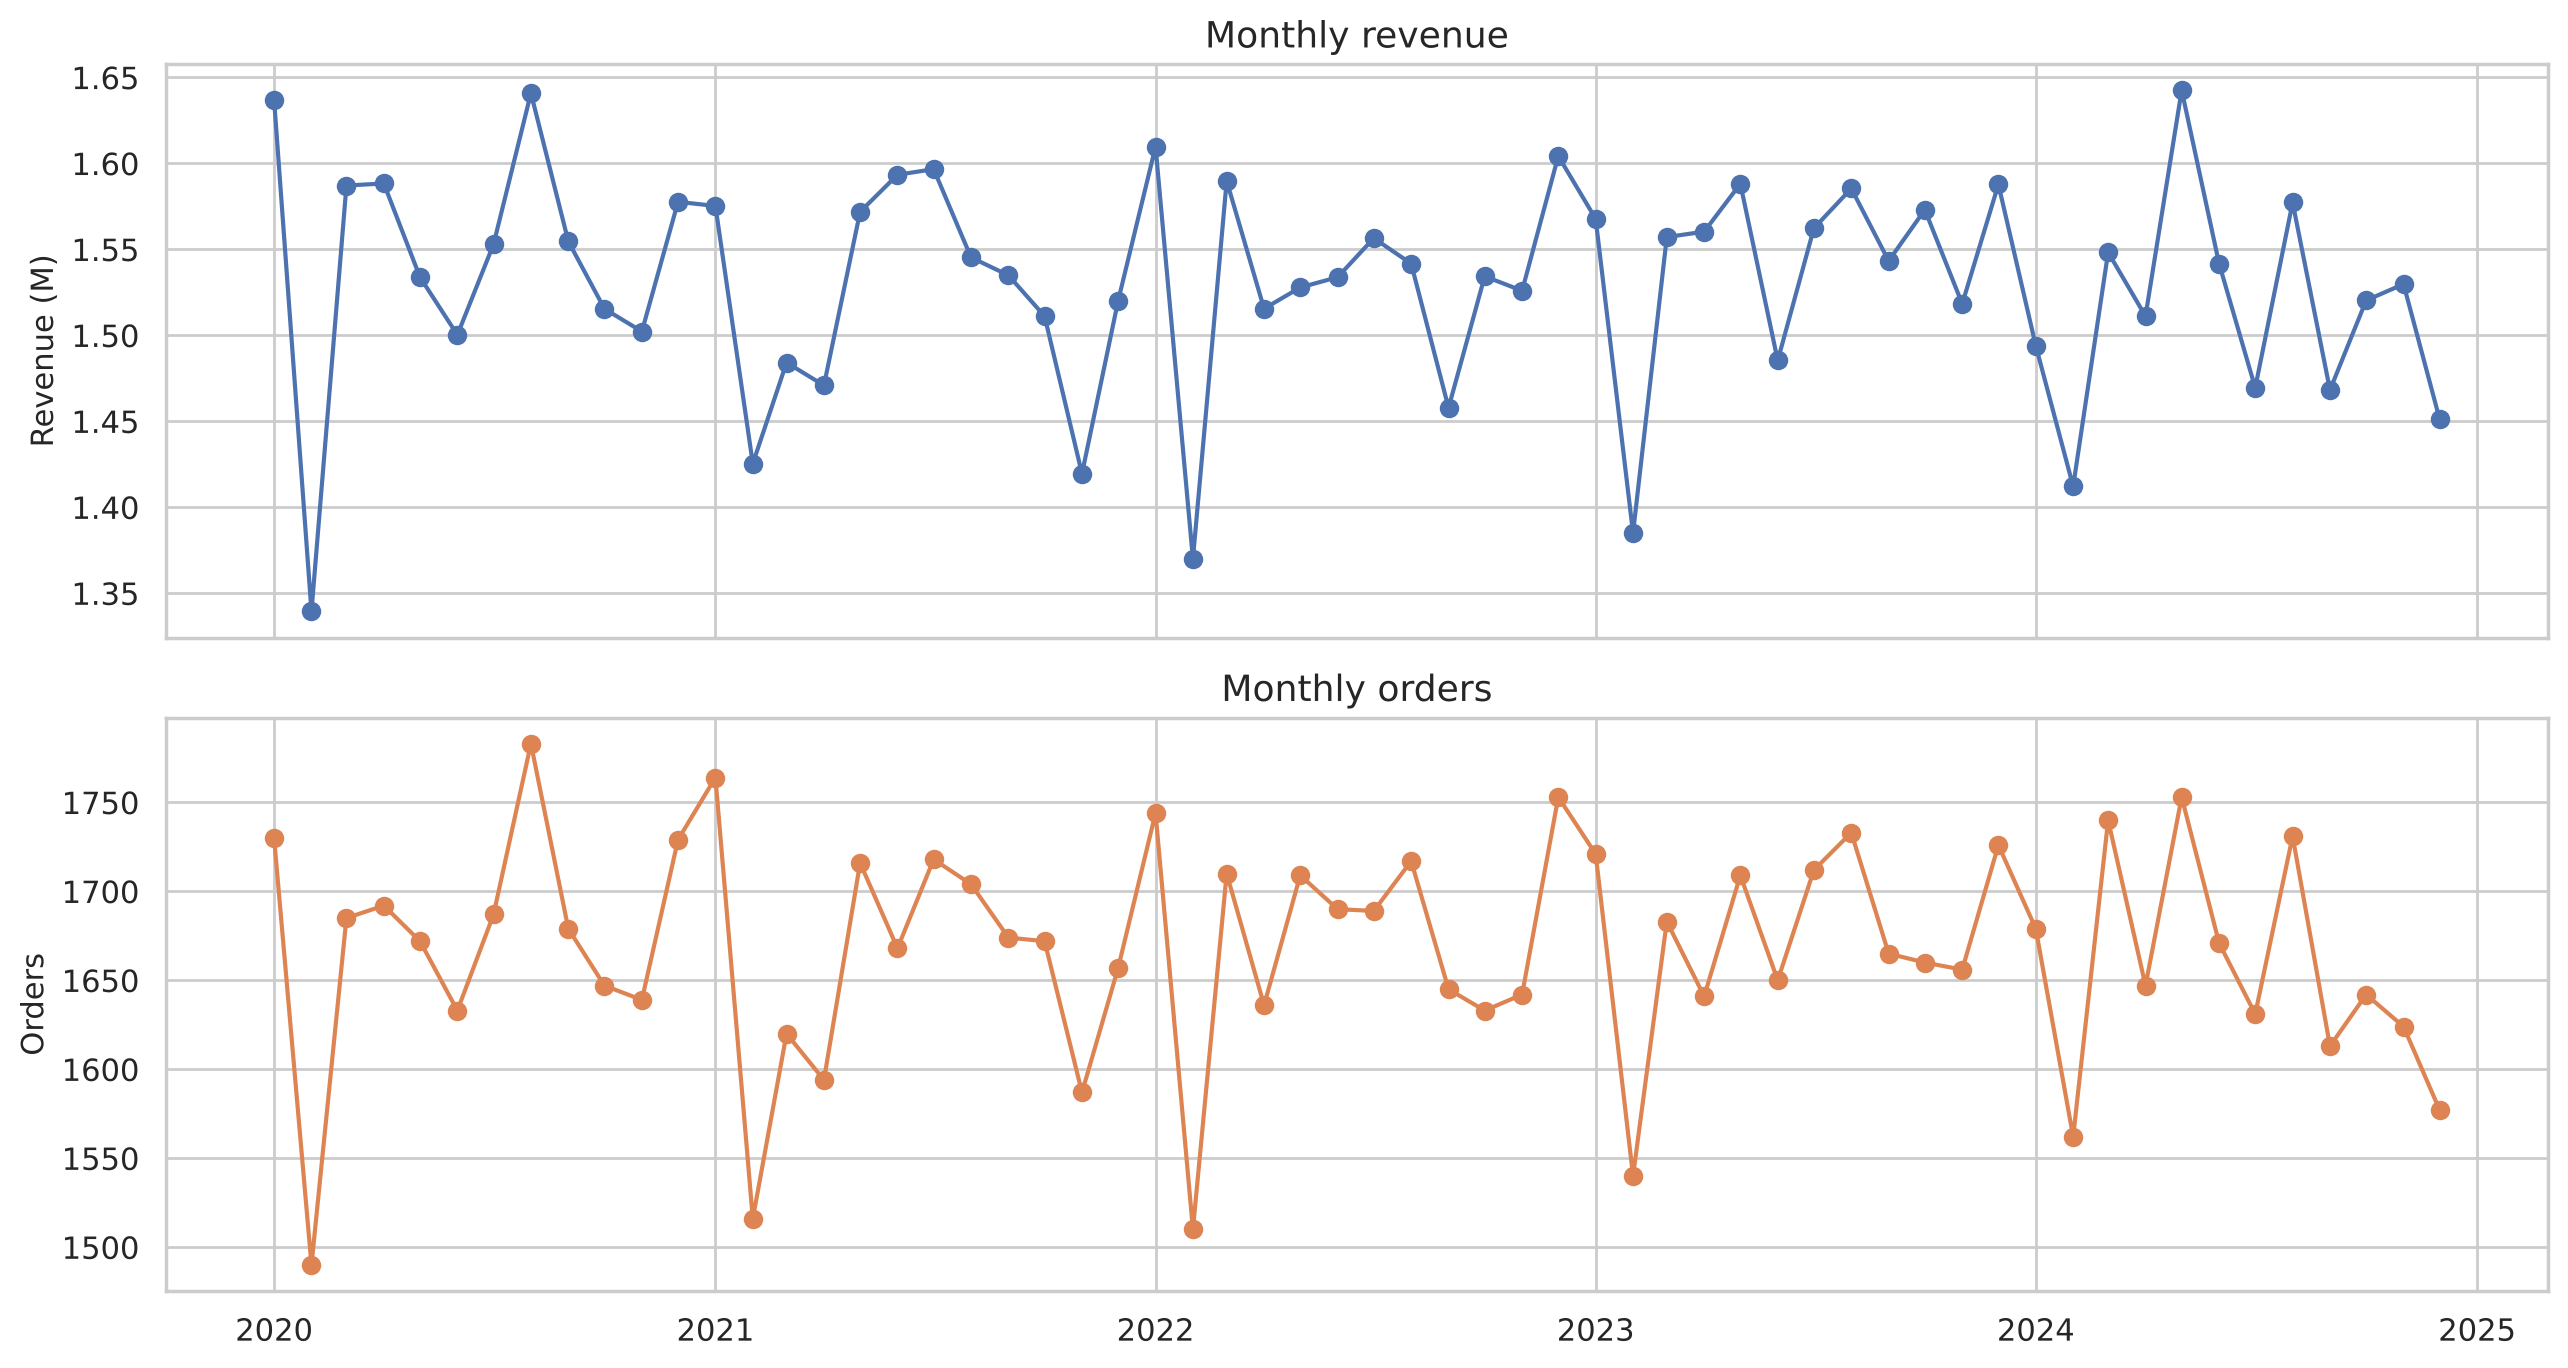

                      sum  count
order_year                      
2020       18,529,864.000  20066
2021       18,248,575.000  19890
2022       18,367,248.000  20078
2023       18,513,912.000  20096
2024       18,166,048.000  19870


In [ ]:
m=df.groupby(['order_year','order_month']).agg(revenue=('TotalAmount','sum'),orders=('OrderID','count')).reset_index()
m['date']=pd.to_datetime(dict(year=m.order_year,month=m.order_month,day=1))
fig,ax=plt.subplots(2,1,figsize=(13,7),sharex=True)
ax[0].plot(m.date,m.revenue/1e6,marker='o'); ax[0].set_ylabel('Revenue (M)'); ax[0].set_title('Monthly revenue')
ax[1].plot(m.date,m.orders,marker='o',color='C1'); ax[1].set_ylabel('Orders'); ax[1].set_title('Monthly orders')
plt.tight_layout(); plt.show()
print(df.groupby('order_year').TotalAmount.agg(['sum','count']).round(0))

                      rev  orders  rev_per_day_K
order_month                                     
1           7,883,801.300    8638         50.900
2           6,931,724.500    7618         49.500
3           7,766,527.700    8438         50.100
4           7,646,203.200    8210         51.000
5           7,864,283.300    8559         50.700
6           7,654,636.800    8312         51.000
7           7,737,925.500    8437         49.900
8           7,890,598.400    8668         50.900
9           7,558,970.800    8276         50.400
10          7,654,243.300    8254         49.400
11          7,495,754.100    8148         50.000
12          7,740,979.000    8442         49.900


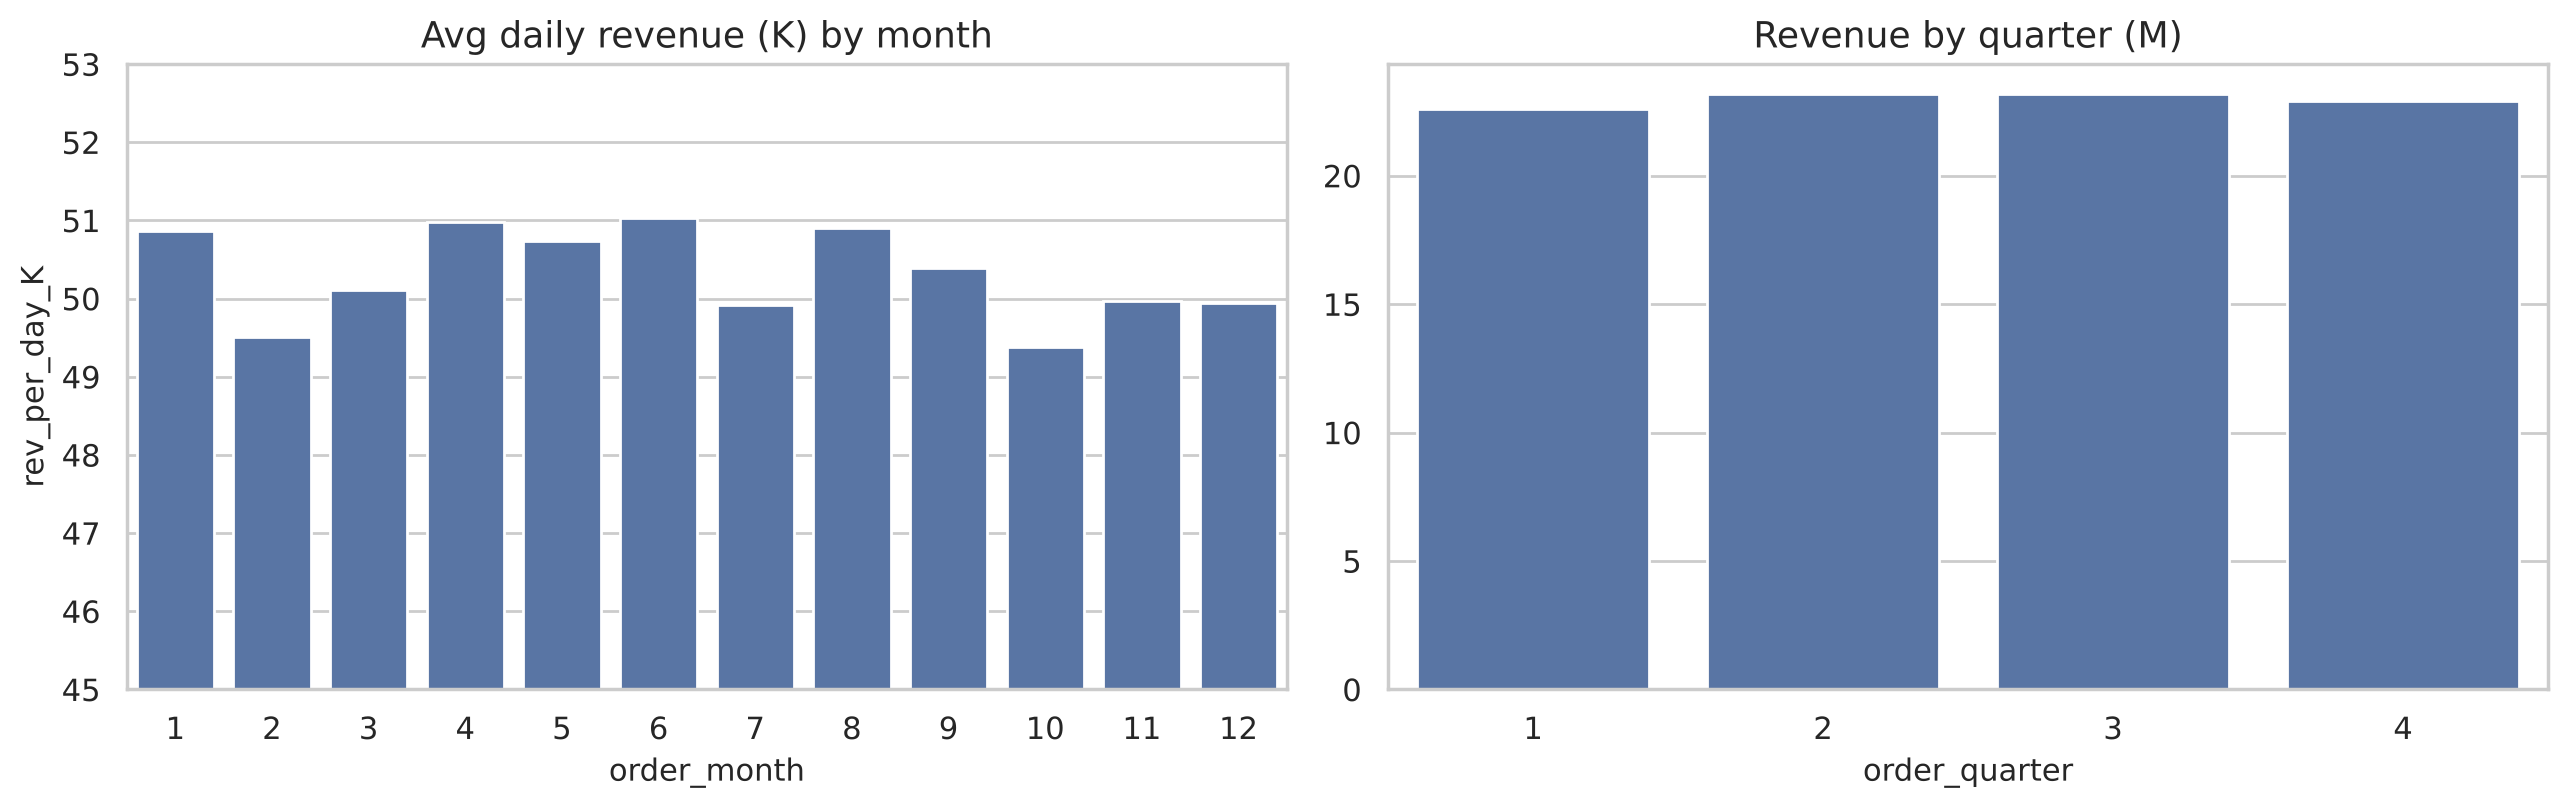

In [ ]:
# Seasonality profile: average per day to remove month-length effect
mm=df.groupby('order_month').agg(rev=('TotalAmount','sum'),orders=('OrderID','count'))
days=pd.Series({mth:pd.Period(f'2021-{mth:02d}').days_in_month for mth in range(1,13)})
mm['rev_per_day_K']=mm.rev/ (days*5)/1e3
print(mm.round(1))
fig,ax=plt.subplots(1,2,figsize=(13,4.2))
sns.barplot(x=mm.index,y=mm.rev_per_day_K,ax=ax[0]); ax[0].set_title('Avg daily revenue (K) by month'); ax[0].set_ylim(45,53)
q=df.groupby('order_quarter').TotalAmount.sum()/1e6; sns.barplot(x=q.index,y=q.values,ax=ax[1]); ax[1].set_title('Revenue by quarter (M)')
plt.tight_layout(); plt.show()

**Insight:** Revenue is flat across 2020–2024 (≈18.2–18.5M per year; 2024 is the lowest, −2% vs 2020). Raw monthly peaks are an artefact of month length (31-day months look bigger; February is smallest). After normalising per day, there is no real seasonal peak and **no Black-Friday / Prime-Day / holiday uplift**.

### 6.2 Day-of-week habits

,orders,avg_value
day_of_week,,
Monday,14150,917.319
Tuesday,14416,925.752
Wednesday,14225,912.265
Thursday,14460,918.724
Friday,14309,924.518
Saturday,14316,914.224
Sunday,14124,914.845


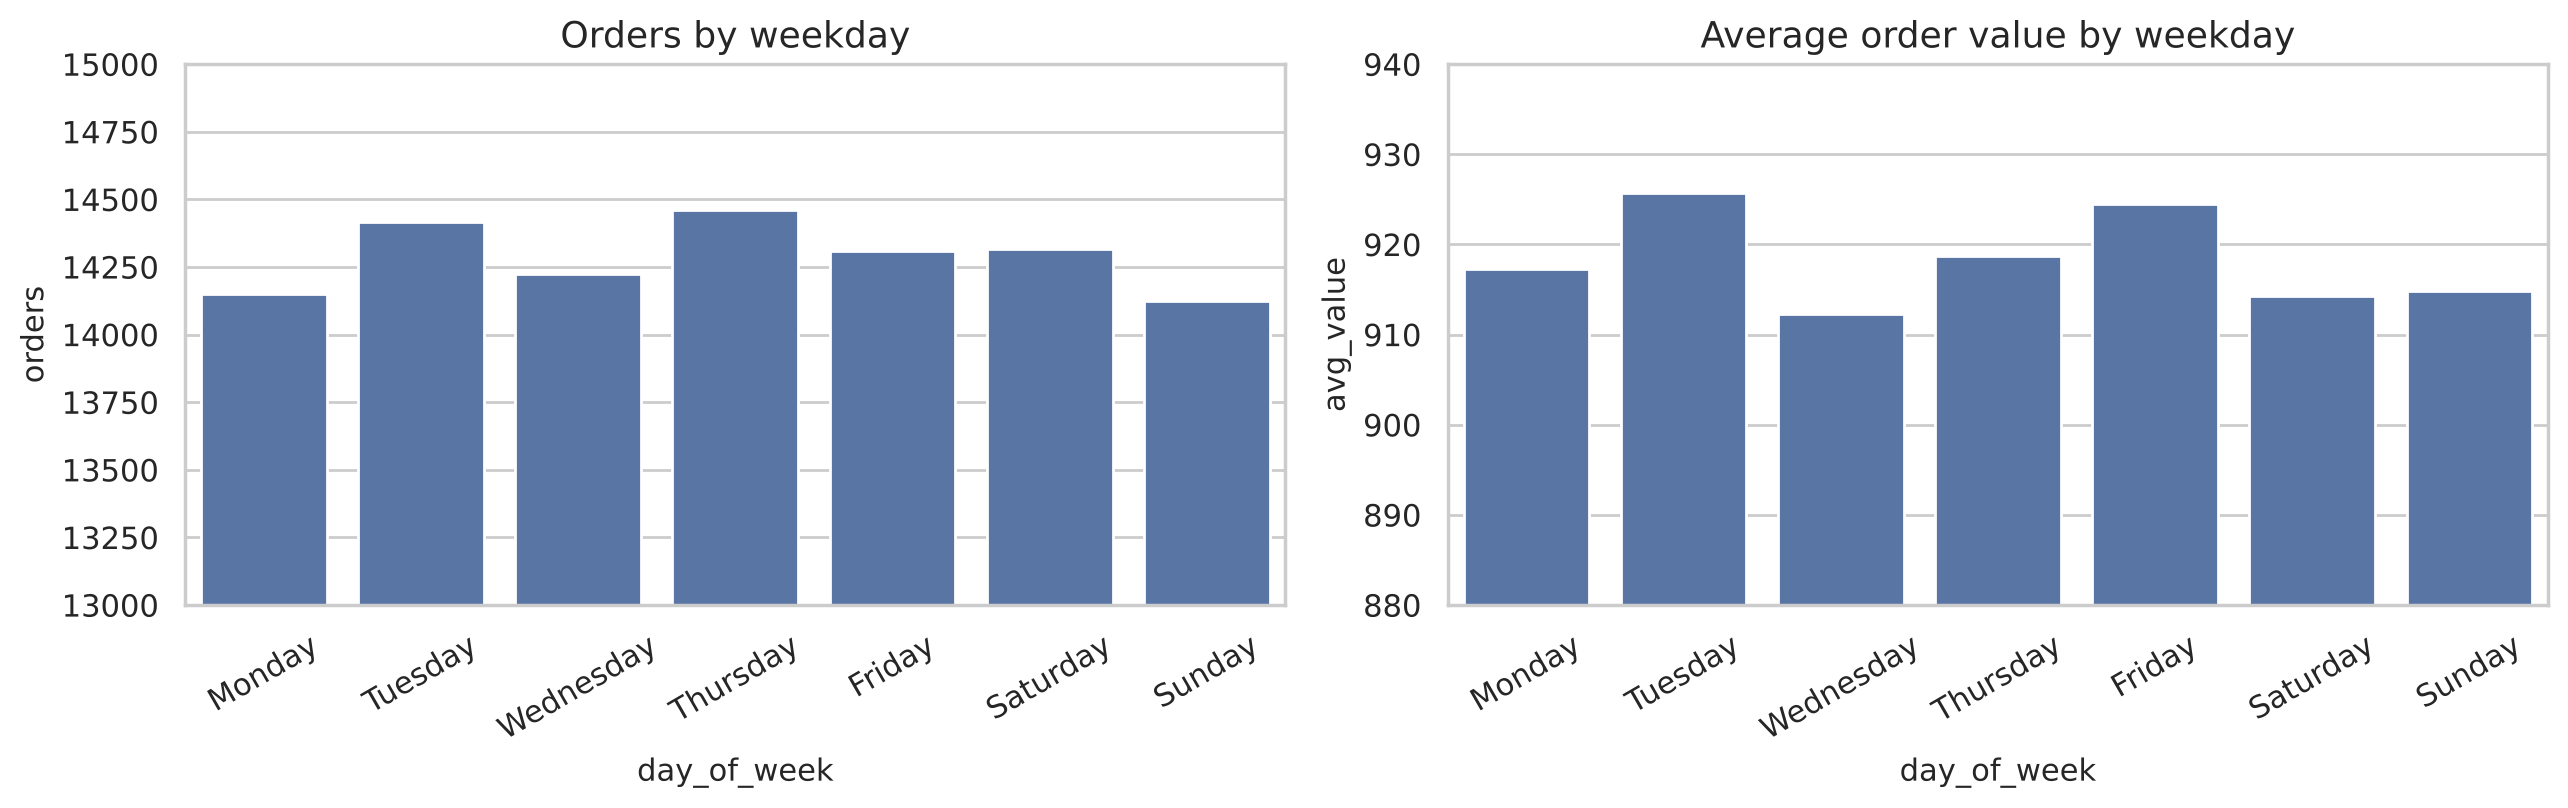

In [ ]:
dw=df.groupby('day_of_week',observed=True).agg(orders=('OrderID','count'),avg_value=('TotalAmount','mean'))
display(dw)
fig,ax=plt.subplots(1,2,figsize=(13,4.2))
sns.barplot(x=dw.index,y=dw.orders,ax=ax[0]); ax[0].set_ylim(13000,15000); ax[0].set_title('Orders by weekday'); ax[0].tick_params(axis='x',rotation=30)
sns.barplot(x=dw.index,y=dw.avg_value,ax=ax[1]); ax[1].set_ylim(880,940); ax[1].set_title('Average order value by weekday'); ax[1].tick_params(axis='x',rotation=30)
plt.tight_layout(); plt.show()

**Insight:** Thursday has the most orders and Tuesday the highest average value, but differences are <3% — weekday and weekend behave alike.

### 6.3 Cancellation spikes & 6.4 category seasonality

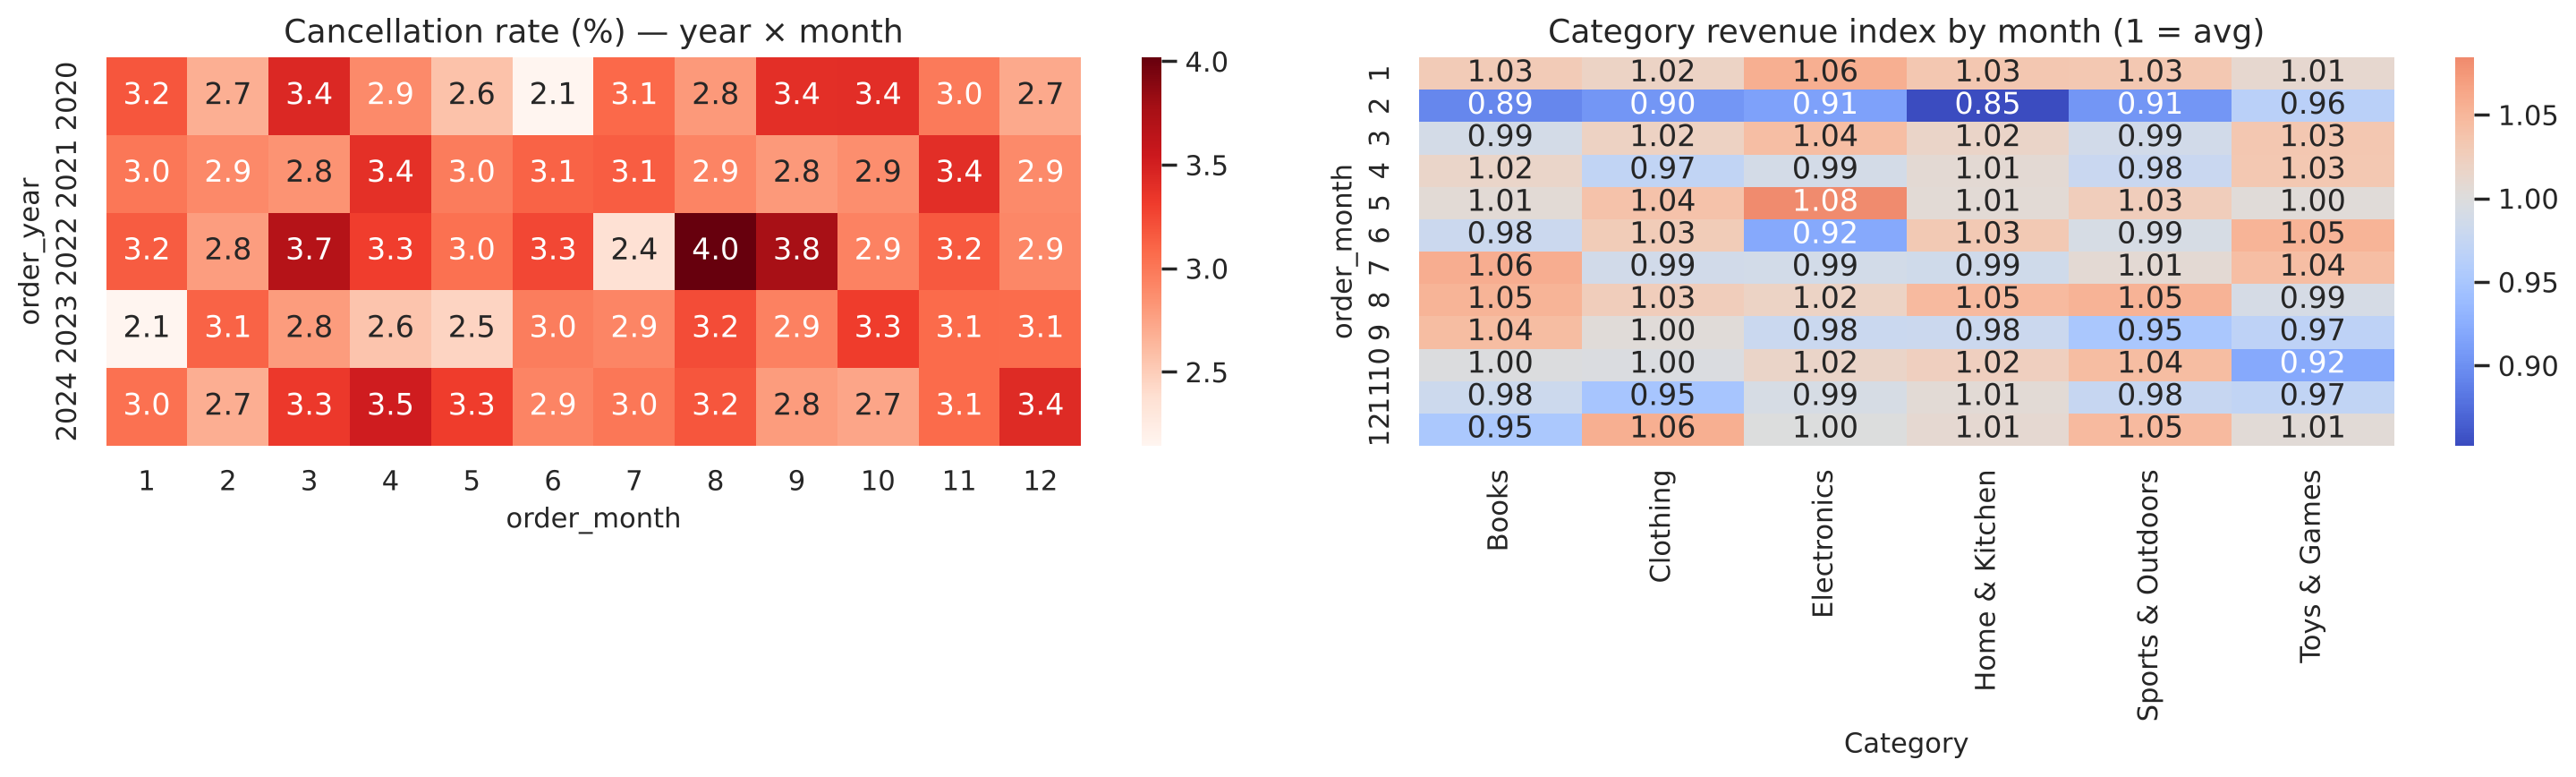

In [ ]:
cm=df.groupby(['order_year','order_month']).is_cancelled.mean().mul(100).unstack()
fig,ax=plt.subplots(1,2,figsize=(15,4.5))
sns.heatmap(cm,annot=True,fmt='.1f',cmap='Reds',ax=ax[0]); ax[0].set_title('Cancellation rate (%) — year × month')
cs=df.pivot_table(index='order_month',columns='Category',values='TotalAmount',aggfunc='sum'); cs=cs.div(cs.mean())
sns.heatmap(cs,annot=True,fmt='.2f',cmap='coolwarm',center=1,ax=ax[1]); ax[1].set_title('Category revenue index by month (1 = avg)')
plt.tight_layout(); plt.show()

**Insight:** Cancellation rates move randomly around 3% with no promotional-period spike. The category seasonality index shows only month-length effects (≈0.9 in Feb), so **no category has a true seasonal surge**.

## 7. Statistical Analysis & Hypothesis Tests

In [ ]:
alpha=0.05
res=[]
# H1: Discount vs Quantity (Spearman, discrete variables)
r,p=stats.spearmanr(df.Discount,df.Quantity); res.append(('Discount ↔ Quantity (Spearman)',f'rho={r:.4f}',p))
# H2: AOV differs by payment method (Kruskal-Wallis; skewed data)
h,p=stats.kruskal(*[g.TotalAmount for _,g in df.groupby('PaymentMethod')]); res.append(('TotalAmount by PaymentMethod (Kruskal)',f'H={h:.2f}',p))
# H3: AOV differs by category
h,p=stats.kruskal(*[g.TotalAmount for _,g in df.groupby('Category')]); res.append(('TotalAmount by Category (Kruskal)',f'H={h:.2f}',p))
# H4: status independent of payment method
chi,p,_,_=stats.chi2_contingency(pd.crosstab(df.PaymentMethod,df.OrderStatus)); res.append(('OrderStatus ⟂ PaymentMethod (Chi²)',f'chi2={chi:.2f}',p))
# H5: status independent of country
chi,p,_,_=stats.chi2_contingency(pd.crosstab(df.Country,df.OrderStatus)); res.append(('OrderStatus ⟂ Country (Chi²)',f'chi2={chi:.2f}',p))
# H6: weekend vs weekday order value
t,p=stats.mannwhitneyu(df[df.is_weekend].TotalAmount,df[~df.is_weekend].TotalAmount); res.append(('Weekend vs weekday value (Mann-Whitney)',f'U={t:,.0f}',p))
# H7: discount level -> order value (strong, mechanical)
h,p=stats.kruskal(*[g.TotalAmount for _,g in df.groupby('Discount')]); res.append(('TotalAmount by Discount (Kruskal)',f'H={h:.1f}',p))
out=pd.DataFrame(res,columns=['Test','Statistic','p-value']); out['Significant (α=0.05)']=out['p-value']<alpha
out['p-value']=out['p-value'].map('{:.2e}'.format); out

,Test,Statistic,p-value,Significant (α=0.05)
0,Discount ↔ Quantity (Spearman),rho=-0.0015,6.33e-01,False
1,TotalAmount by PaymentMethod (Kruskal),H=5.47,3.61e-01,False
2,TotalAmount by Category (Kruskal),H=6.88,2.30e-01,False
3,OrderStatus ⟂ PaymentMethod (Chi²),chi2=14.99,7.77e-01,False
4,OrderStatus ⟂ Country (Chi²),chi2=15.38,4.97e-01,False
5,Weekend vs weekday value (Mann-Whitney),"U=1,013,305,830",2.99e-01,False
6,TotalAmount by Discount (Kruskal),H=856.7,8.78e-182,True


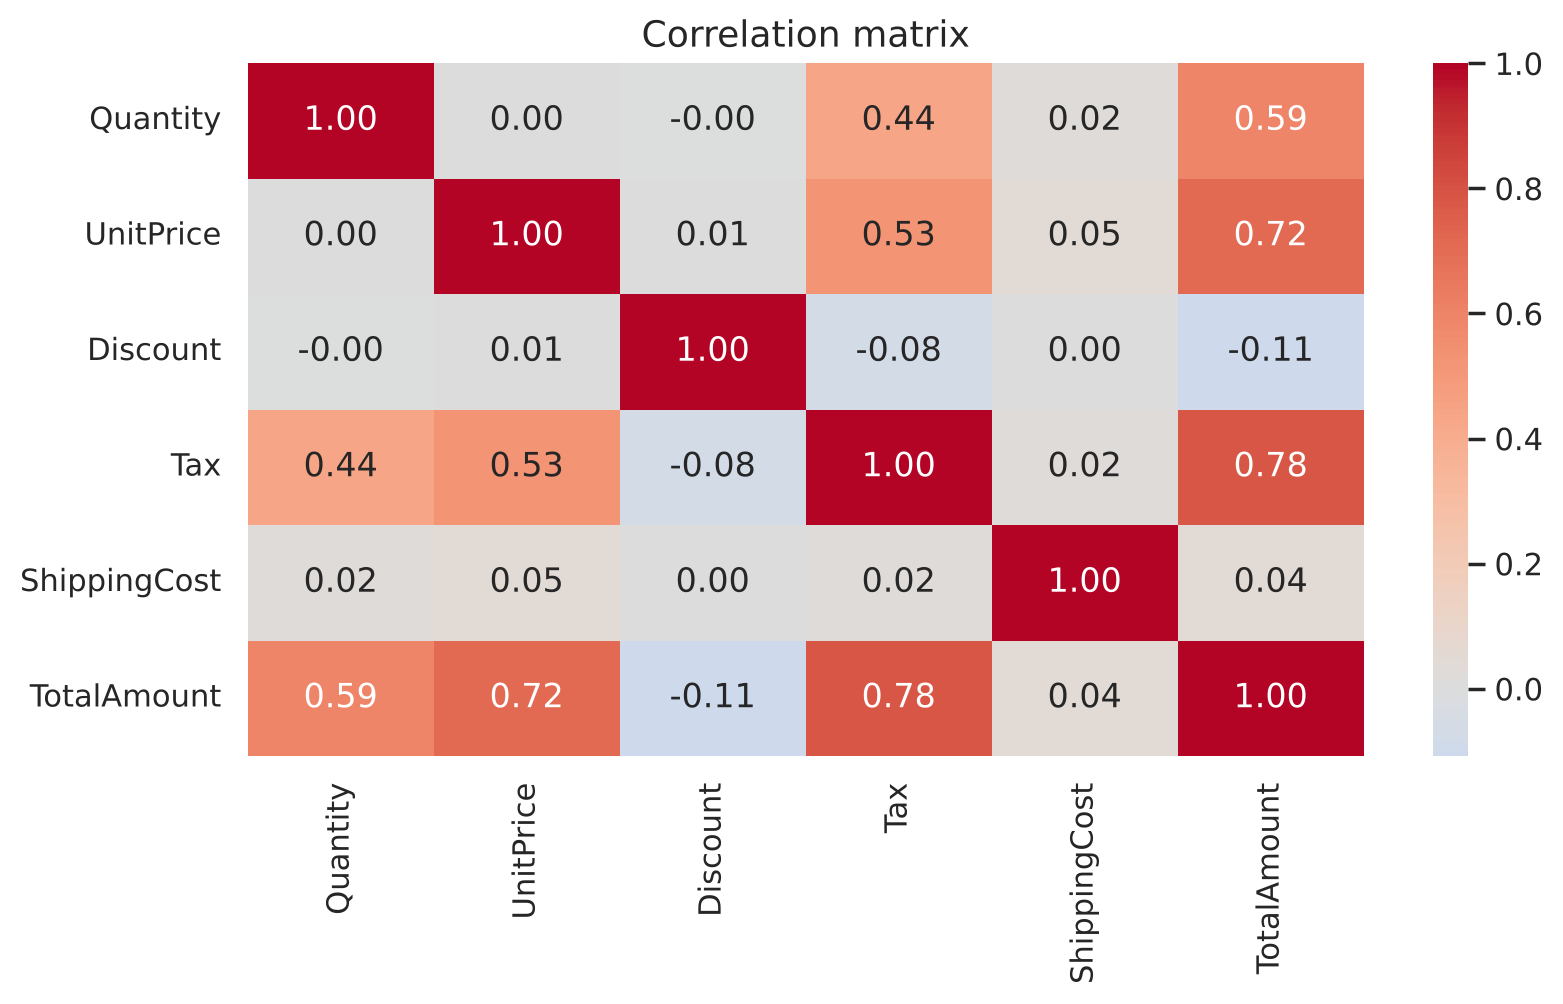

In [ ]:
# Which variables actually move TotalAmount?
num=['Quantity','UnitPrice','Discount','Tax','ShippingCost','TotalAmount']
sns.heatmap(df[num].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0); plt.title('Correlation matrix'); plt.show()

**Interpretation**
- Only the *mechanical* relationships are real: TotalAmount rises with Quantity (r≈0.60) and UnitPrice, and falls with Discount.
- All behavioural hypotheses (payment method, category, country, weekend, discount→volume) are **not significant** — we fail to reject independence/equality.
- Business implication: segmenting by these attributes will not separate high- and low-performing orders in this data.

## 8. Business Recommendations
| # | Finding (evidence) | Recommendation | Expected impact |
|---|---|---|---|
| 1 | Discounts don't change units: r≈0, ~3.0 units at every discount level; AOV falls ~26% from 0%→30% | Cut blanket discounts, particularly ≥20%; reserve promotions for clearance / acquisition and test with A/B holdouts | Protect margin without losing volume |
| 2 | Only 74.6% delivered, ~6% cancelled/returned, 19% still Shipped/Pending | Track fulfillment SLAs, audit Pending orders, add pre-dispatch confirmation | Recover part of the ~6% leakage (≈5.6M of lost order value over 5 years) |
| 3 | Shipping is flat random (0–15) → heavy burden on small orders | Introduce a free-shipping threshold / tiered shipping tied to order value | Higher basket size, fewer small-order drop-offs |
| 4 | Quantity (r≈0.6) and UnitPrice drive order value | Bundles / "buy 4–5" offers and cross-sell on high-price items instead of discounts | Raise AOV |
| 5 | Revenue flat 2020–24 (−2%); no seasonal peaks | Build a calendar of seasonal campaigns (festive, Prime-Day-type) — current data shows no event uplift | Break the plateau |
| 6 | 70% of orders from the US; India 15% | Defend US share; pilot growth investment in India/Canada | Reduce concentration risk |
| 7 | Categories, brands, payment methods, countries all within ~2–3% | Avoid segment-specific strategies unless new data (margins, CAC, ratings) shows real differences; invest in collecting it | Avoid wasted effort |
| 8 | Seller cancellation differences are noise (~50 orders each) | Use rolling, larger-volume scorecards before penalising sellers | Fairer vendor management |

## Limitations
- **Synthetic data**: random uniform patterns, inconsistent geography, product–category mismatch, no real seasonality.
- No cost/margin, customer demographics, ratings or return reasons — so profit and satisfaction cannot be analysed.
- `TotalAmount` for Cancelled/Returned orders is still counted in revenue figures; a production analysis should net these out (≈6% of revenue).